# Antibiotic-aligned consumer-resource control

Run all cells. Balanced feeding categories, fixed resistance traits and resistance growth cost match the antibiotic model, but there is no antibiotic and no mortality. The former starvation comparison is now a resistance-cost comparison. All species can persist while relative abundance and Shannon diversity change. No shared beta-lactamase protection is included.

In [1]:
import sys,types
from pathlib import Path
from dataclasses import replace
import numpy as np
import pandas as pd
from IPython.display import display,Image
model_source = '"""Antibiotic-aligned batch consumer-resource model, with no drug state.\n\nSame balanced community generator, IC50/resistance traits and growth cost as the\nuploaded antibiotic model. Basal/starvation mortality are zero. IC50 is retained\nas a trait for matching only, and has no direct effect on these ODEs.\n"""\nfrom dataclasses import dataclass, asdict\nimport numpy as np\nimport pandas as pd\nfrom scipy.integrate import solve_ivp\nfrom scipy.stats import truncnorm\n\n@dataclass\nclass Config:\n    # Legacy mortality flags/parameters are compatibility-only; deaths are zero.\n    variable_affinity: bool = True\n    starvation_mortality: bool = False\n    structured_community: bool = False\n    affinity_log_sd: float = .7\n    starvation_mean: float = .06\n    starvation_sd: float = .015\n    seed: int = 42\n    n_species: int = 25\n    t_end: float = 300.\n    n_times: int = 1201\n    growth_mean: float = .5\n    growth_sd: float = .15\n    growth_reference: float = 1.\n    death_mean: float = .01\n    death_sd: float = .003\n    initial_biomass: float = .01\n    initial_resource: float = 1.\n    half_saturation: float = .1\n    leakage: float = .2\n    extinction_fraction: float = 1e-6\n\n    ic50_min: float = 0.05\n    ic50_max: float = 2.0\n    resistance_cost_max: float = 0.20\n\nFOODS = [\'R0\', \'M1\', \'M2\']\n\n\ndef truncated(rng, mean, sd, low, high, size):\n    return truncnorm.rvs(\n        (low - mean) / sd,\n        (high - mean) / sd,\n        loc=mean,\n        scale=sd,\n        size=size,\n        random_state=rng,\n    )\n\n\ndef generate(c=Config()):\n    if c.n_species < 3 or c.n_times < 2 or c.t_end <= 0:\n        raise ValueError(\'Require >=3 species, >=2 output times, and positive duration\')\n    if not (0 <= c.leakage < 1 and 0 < c.extinction_fraction < 1):\n        raise ValueError(\'Require 0<=leakage<1 and 0<extinction_fraction<1\')\n    if min(c.growth_sd, c.death_sd, c.growth_reference,\n           c.initial_biomass, c.half_saturation) <= 0 or c.initial_resource < 0:\n        raise ValueError(\'Invalid positive scale or initial resource\')\n    if c.ic50_min <= 0 or c.ic50_max < c.ic50_min:\n        raise ValueError(\'Require 0 < ic50_min <= ic50_max\')\n    if not (0 <= c.resistance_cost_max < 1):\n        raise ValueError(\'Require 0 <= resistance_cost_max < 1\')\n\n    rng = np.random.default_rng(c.seed)\n    score = truncated(rng, c.growth_mean, c.growth_sd, 0, 1, c.n_species)\n\n    # Preserve the original RNG sequence for community construction, but baseline\n    # and starvation mortality are intentionally not used in the new model.\n    _legacy_death_draw = truncated(rng, c.death_mean, c.death_sd, 0, np.inf, c.n_species)\n\n    # Keep the old RNG consumption so the other random traits remain reproducible,\n    # but replace the random food-category frequencies with a balanced design.\n    _legacy_codes_draw = rng.integers(1, 8, c.n_species)\n\n    # Seven nonempty food subsets encoded as bit masks:\n    # 1=R0, 2=M1, 3=R0+M1, 4=M2, 5=R0+M2,\n    # 6=M1+M2, 7=R0+M1+M2. Repeating 1..7 makes category\n    # counts differ by at most one; a separate RNG shuffles which species\n    # receives which category without changing the counts.\n    codes = np.resize(np.arange(1, 8, dtype=int), c.n_species)\n    food_rng = np.random.default_rng(c.seed + 300000)\n    food_rng.shuffle(codes)\n    mask = ((codes[:, None] >> np.arange(3)) & 1).astype(bool)\n    weights = rng.dirichlet(np.ones(3), c.n_species) * mask\n    weights /= weights.sum(axis=1, keepdims=True)\n\n    # Retained energy fractions: R0 leaks, metabolites do not.\n    retain = np.array([1 - c.leakage, 1., 1.])\n\n    # Preliminary capacity; final capacity is recomputed below after applying\n    # the resistance fitness cost.\n    capacity = score * c.growth_reference / (weights @ retain)\n    uptake = capacity[:, None] * weights\n    split = rng.dirichlet([1., 1.], c.n_species)\n\n    # Extra draws use an independent generator so original community draws stay fixed.\n    extra = np.random.default_rng(c.seed + 100000)\n    Kdraw = extra.lognormal(\n        np.log(c.half_saturation),\n        c.affinity_log_sd,\n        (c.n_species, 3),\n    )\n    Kdraw = np.clip(Kdraw, .01, 1.)\n\n    # Keep these legacy draws only to preserve the old RNG sequence for biomass/structure.\n    _legacy_starve_draw = truncated(\n        extra, c.starvation_mean, c.starvation_sd, 0, .15, c.n_species\n    )\n    biomass_draw = extra.lognormal(0, 1., c.n_species)\n\n    # Use a separate RNG for resistance so adding antibiotics does not alter K/biomass draws.\n    antibiotic_rng = np.random.default_rng(c.seed + 200000)\n    resistance = antibiotic_rng.uniform(0, 1, c.n_species)\n    IC50 = c.ic50_min * (c.ic50_max / c.ic50_min) ** resistance\n\n    # Linear fitness cost of resistance. This affects growth even when A=0.\n    # rho=0 -> no cost; rho=1 -> resistance_cost_max fractional reduction\n    # in maximum resource-supported growth.\n    resistance_fitness_cost = c.resistance_cost_max * resistance\n    growth_multiplier = 1.0 - resistance_fitness_cost\n    intrinsic_mu_max = score * c.growth_reference\n    effective_mu_max = intrinsic_mu_max * growth_multiplier\n\n    # Optional legacy structure for leakage/secretion and initial biomass.\n    # Feeding categories remain balanced even when this flag is enabled.\n    if c.structured_community:\n        types = extra.choice([0, 1, 2, 3], c.n_species, p=[.25, .25, .25, .25])\n        # Choose an R0 consumer to guarantee at least one R0 user secretes both metabolites.\n        r0_users = np.flatnonzero(mask[:, 0])\n        if len(r0_users):\n            types[r0_users[0]] = 3\n        leak = np.where(types == 0, 0., c.leakage)\n        split = extra.dirichlet([1., 1.], c.n_species)\n        split[types == 1] = [1., 0.]\n        split[types == 2] = [0., 1.]\n    else:\n        leak = np.full(c.n_species, c.leakage)\n\n    # Category codes remain the balanced codes generated above.\n    codes = (mask * np.array([1, 2, 4])).sum(axis=1).astype(int)\n\n    retain = np.column_stack([1 - leak, np.ones((c.n_species, 2))])\n\n    # Normalize uptake capacity so growth at saturating permitted resources is\n    # the resistance-cost-adjusted mu_max. Therefore resistance carries a\n    # growth penalty even in the no-antibiotic control.\n    capacity = effective_mu_max / np.sum(weights * retain, axis=1)\n    uptake = capacity[:, None] * weights\n\n    initial = (\n        c.initial_biomass * biomass_draw / biomass_draw.sum()\n        if c.structured_community\n        else np.full(c.n_species, c.initial_biomass / c.n_species)\n    )\n    K = Kdraw if c.variable_affinity else np.full_like(Kdraw, c.half_saturation)\n\n    # These legacy columns are retained only so the old analysis_tools.py does not break.\n    # They are zero because the no-antibiotic aligned control has no mortality.\n    baseline_death = np.zeros(c.n_species)\n    starvation_increment = np.zeros(c.n_species)\n\n    table = pd.DataFrame({\n        \'species\': [f\'S{i+1:02d}\' for i in range(c.n_species)],\n        \'growth_score\': score,\n        \'intrinsic_mu_max\': intrinsic_mu_max,\n        \'mu_max\': effective_mu_max,\n        \'resistance_growth_multiplier\': growth_multiplier,\n        \'resistance_fitness_cost\': resistance_fitness_cost,\n        \'death_rate\': baseline_death,\n        \'total_uptake_capacity\': capacity,\n        \'M1_secretion_share\': split[:, 0],\n        \'M2_secretion_share\': split[:, 1],\n        \'initial_biomass\': initial,\n        \'starvation_death_increment\': starvation_increment,\n        \'leakage_fraction\': leak,\n        \'food_category_code\': codes,\n        \'resistance\': resistance,\n        \'IC50\': IC50,\n    })\n\n\n    category_names = {\n        1: \'R0\',\n        2: \'M1\',\n        3: \'R0+M1\',\n        4: \'M2\',\n        5: \'R0+M2\',\n        6: \'M1+M2\',\n        7: \'R0+M1+M2\',\n    }\n    table[\'food_category\'] = [category_names[int(code)] for code in codes]\n\n    for j, f in enumerate(FOODS):\n        table[f\'can_consume_{f}\'] = mask[:, j]\n        table[f\'K_{f}\'] = K[:, j]\n        table[f\'preference_{f}\'] = weights[:, j]\n        table[f\'uptake_max_{f}\'] = uptake[:, j]\n\n    return {\n        \'config\': c,\n        \'table\': table,\n        \'uptake\': uptake,\n        \'split\': split,\n        \'retain\': retain,\n        \'K\': K,\n        \'leak\': leak,\n        \'initial\': initial,\n        \'starve\': starvation_increment,  # legacy compatibility only\n        \'resistance\': resistance,\n        \'IC50\': IC50,\n        \'resistance_fitness_cost\': resistance_fitness_cost,\n        \'growth_multiplier\': growth_multiplier,\n        \'food_category_code\': codes,\n    }\n\n\ndef fluxes(N,R,p):\n    c=p[\'config\']\n    u=p[\'uptake\']*np.maximum(R,0)/(p[\'K\']+np.maximum(R,0))\n    gross=np.sum(u*p[\'retain\'],axis=1)\n    consumed=np.maximum(N,0)[:,None]*u\n    secretion=np.sum(consumed[:,0,None]*p[\'leak\'][:,None]*p[\'split\'],axis=0)\n    return gross,consumed,secretion\n\ndef death_rates(gross,p):\n    """No basal or starvation mortality, matching antibiotic model at A=0."""\n    return np.zeros(p[\'config\'].n_species)\n\ndef simulate(p):\n    c=p[\'config\']; n=c.n_species; death=p[\'table\'].death_rate.to_numpy()\n    N0=p[\'initial\']; cutoff=c.initial_biomass/n*c.extinction_fraction\n    # State: N, R0/M1/M2, cumulative mortality, biomass removed at cutoffs.\n    y=np.r_[N0,c.initial_resource,0.,0.,0.,0.]\n    active=np.ones(n,dtype=bool); extinction=np.full(n,np.nan)\n    times=np.linspace(0,c.t_end,c.n_times); states=np.empty((len(times),n+5))\n    t=0.; filled=np.zeros(len(times),dtype=bool)\n    while t < c.t_end:\n        def rhs(t,y):\n            N=np.maximum(y[:n],0)*active; R=y[n:n+3]\n            gross,consumed,secreted=fluxes(N,R,p)\n            death=death_rates(gross,p)\n            return np.r_[N*(gross-death),-consumed.sum(axis=0)+np.r_[0.,secreted],\n                         N@death,0.]\n        events=[]; ids=np.flatnonzero(active)\n        for i in ids:\n            def event(t,y,i=i): return y[i]-cutoff\n            event.terminal=True; event.direction=-1; events.append(event)\n        sol=solve_ivp(rhs,(t,c.t_end),y,method=\'DOP853\',rtol=1e-8,atol=1e-13,\n                      dense_output=True,events=events or None,max_step=2.)\n        if not sol.success: raise RuntimeError(sol.message)\n        end=sol.t[-1]; sel=(times>=t)&(times<=end)&(~filled)\n        if sel.any():\n            states[sel]=sol.sol(times[sel]).T; filled[sel]=True\n        y=sol.y[:,-1].copy(); t=end\n        if t>=c.t_end: break\n        hits=[ids[k] for k,e in enumerate(sol.t_events) if len(e)]\n        hits=list(set(hits+list(np.flatnonzero(active & (y[:n]<=cutoff*(1+1e-8))))))\n        if not hits: raise RuntimeError(\'Extinction event without a crossing\')\n        y[-1]+=y[hits].sum(); y[hits]=0; active[hits]=False; extinction[hits]=t\n    assert filled.all()\n    N=np.maximum(states[:,:n],0); R=np.maximum(states[:,n:n+3],0)\n    gross=np.array([fluxes(N[k],R[k],p)[0] for k in range(len(times))])\n    deaths=np.array([death_rates(g,p) for g in gross])\n    result={\'t\':times,\'N\':N,\'R\':R,\'gross\':gross,\'net\':gross-deaths,\'death_rates\':deaths,\n            \'mortality\':N*deaths,\'extinction\':extinction,\'death_loss\':states[:,-2],\n            \'cutoff_loss\':states[:,-1],\'cutoff\':cutoff}\n    budget=N.sum(axis=1)+R.sum(axis=1)+states[:,-2]+states[:,-1]\n    result[\'budget_error\']=budget-(c.initial_biomass+c.initial_resource)\n    assert np.max(np.abs(result[\'budget_error\']))<1e-6\n    assert states[:,:n+3].min()>-1e-9\n    return result\n\ndef summarize(p,r):\n    df=p[\'table\'].copy(); df[\'final_biomass\']=r[\'N\'][-1]\n    df[\'peak_biomass\']=r[\'N\'].max(axis=0)\n    df[\'biomass_time_integral\']=np.trapezoid(r[\'N\'],r[\'t\'],axis=0)\n    df[\'extinction_time\']=r[\'extinction\']; df[\'survived\']=np.isnan(r[\'extinction\'])\n    df[\'final_percent\']=100*r[\'N\'][-1]/max(r[\'N\'][-1].sum(),1e-300)\n    return df\n\ndef export(p,r,out):\n    from pathlib import Path\n    import json\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    summarize(p,r).to_csv(out/\'species_summary.csv\',index=False)\n    frames=[]\n    for i,name in enumerate(p[\'table\'].species):\n        frames.append(pd.DataFrame({\'time\':r[\'t\'],\'species\':name,\'biomass\':r[\'N\'][:,i],\n          \'percent\':100*r[\'N\'][:,i]/np.maximum(r[\'N\'].sum(axis=1),1e-300),\n          \'gross_growth_rate\':r[\'gross\'][:,i],\'death_rate\':r[\'death_rates\'][:,i],\n          \'net_growth_rate\':r[\'net\'][:,i], \'biomass_death_flux\':r[\'mortality\'][:,i]}))\n    pd.concat(frames).to_csv(out/\'species_timeseries.csv\',index=False)\n    pd.DataFrame({\'time\':r[\'t\'],**{f:r[\'R\'][:,j] for j,f in enumerate(FOODS)},\n      \'total_biomass\':r[\'N\'].sum(axis=1),\'cumulative_death_loss\':r[\'death_loss\'],\n      \'cumulative_cutoff_loss\':r[\'cutoff_loss\'],\'budget_error\':r[\'budget_error\']}).to_csv(out/\'community_timeseries.csv\',index=False)\n    (out/\'config.json\').write_text(json.dumps(asdict(p[\'config\']),indent=2))\n'
analysis_source = '"""Matched scenario comparisons and captions."""\nfrom pathlib import Path\nfrom dataclasses import replace\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom model import Config,generate,simulate,summarize,export,FOODS\n\nSCENARIOS={\n \'baseline\':dict(variable_affinity=False,resistance_cost_max=0.,structured_community=False),\n \'affinity\':dict(variable_affinity=True,resistance_cost_max=0.,structured_community=False),\n \'cost\':dict(variable_affinity=False,resistance_cost_max=.20,structured_community=False),\n \'both\':dict(variable_affinity=True,resistance_cost_max=.20,structured_community=False),\n \'structured\':dict(variable_affinity=True,resistance_cost_max=.20,structured_community=True)}\n\ndef diversity(r):\n    total=r[\'N\'].sum(axis=1);alive=total>0\n    shares=np.divide(r[\'N\'],total[:,None],out=np.zeros_like(r[\'N\']),where=total[:,None]>0)\n    H=-np.sum(shares*np.log(np.maximum(shares,1e-300)),axis=1);H[~alive]=np.nan\n    effective=np.exp(H);richness=(r[\'N\']>0).sum(axis=1)\n    return pd.DataFrame({\'time\':r[\'t\'],\'total_biomass\':total,\'shannon\':H,\'effective_species\':effective,\'richness\':richness})\n\ndef run_scenarios(config=Config(),out=\'outputs\'):\n    root=Path(out);root.mkdir(exist_ok=True,parents=True);runs={};rows=[]\n    for name,settings in SCENARIOS.items():\n        p=generate(replace(config,**settings));r=simulate(p);runs[name]=(p,r)\n        folder=root/name;export(p,r,folder);d=diversity(r);d.to_csv(folder/\'diversity_timeseries.csv\',index=False)\n        p[\'table\'].select_dtypes(include=\'number\').describe().T.to_csv(folder/\'realized_parameter_spread.csv\')\n        df=summarize(p,r);rows.append({\'scenario\':name,\'survivors\':int(df.survived.sum()),\'final_biomass\':r[\'N\'][-1].sum(),\'final_shannon\':d.shannon.iloc[-1],\'max_budget_error\':abs(r[\'budget_error\']).max()})\n    summary=pd.DataFrame(rows);summary.to_csv(root/\'scenario_summary.csv\',index=False)\n    return runs,summary\n\ndef make_figures(runs,out=\'outputs\'):\n    out=Path(out);figures=[];plt.rcParams.update({\'figure.dpi\':120,\'axes.spines.top\':False,\'axes.spines.right\':False})\n    def save(fig,name,caption):\n        fig.tight_layout();path=out/(name+\'.png\');fig.savefig(path,bbox_inches=\'tight\');plt.close(fig);figures.append((path,caption))\n    fig,axs=plt.subplots(2,2,figsize=(11,7))\n    for name,(p,r) in runs.items():\n        d=diversity(r)\n        for ax,col in zip(axs.flat,[\'shannon\',\'effective_species\',\'richness\',\'total_biomass\']):ax.plot(d.time,d[col],label=name);ax.set(xlabel=\'Time\',ylabel=col.replace(\'_\',\' \'))\n    axs[0,0].legend(fontsize=8);axs[1,1].set_yscale(\'log\')\n    save(fig,\'01_scenario_diversity\',\'Figure 1. Shannon H (natural logarithm), effective diversity exp(H), species remaining above the cutoff, and total living biomass. The first four scenarios share intrinsic growth, resistance, food permissions, secretion and initial abundance draws; growth capacity differs when resistance cost is enabled. The structured scenario changes several traits jointly, so its difference cannot be attributed to one mechanism. Shannon is undefined when total biomass is zero.\')\n    p,r=runs[\'both\'];df=p[\'table\'];colors=plt.cm.turbo(np.linspace(0,1,len(df)))\n    fig,axs=plt.subplots(2,3,figsize=(13,8))\n    axs[0,0].hist(df.mu_max,bins=8);axs[0,0].set(xlabel=\'Maximum gross growth\',ylabel=\'Species count\')\n    axs[0,1].scatter(df.resistance,df.resistance_growth_multiplier);axs[0,1].set(xlabel=\'Resistance score\',ylabel=\'Growth multiplier\')\n    im=axs[0,2].imshow(p[\'K\'],aspect=\'auto\',norm=plt.matplotlib.colors.LogNorm());fig.colorbar(im,ax=axs[0,2],label=\'Half-saturation K\');axs[0,2].set(xticks=range(3),xticklabels=FOODS,ylabel=\'Species index\')\n    im=axs[1,0].imshow(p[\'uptake\'],aspect=\'auto\');fig.colorbar(im,ax=axs[1,0],label=\'Maximum uptake\');axs[1,0].set(xticks=range(3),xticklabels=FOODS,ylabel=\'Species index\')\n    axs[1,1].bar(range(len(df)),p[\'split\'][:,0],label=\'M1\');axs[1,1].bar(range(len(df)),p[\'split\'][:,1],bottom=p[\'split\'][:,0],label=\'M2\');axs[1,1].legend();axs[1,1].set(xlabel=\'Species index\',ylabel=\'Leaked-energy allocation\')\n    groups=df[[f\'can_consume_{f}\' for f in FOODS]].apply(lambda row:\'+\'.join(f for f,v in zip(FOODS,row) if v),axis=1).value_counts()\n    axs[1,2].barh(groups.index,groups.values);axs[1,2].set(xlabel=\'Species count\',ylabel=\'Permitted foods\')\n    save(fig,\'02_species_traits\',\'Figure 2. Realized traits in the both scenario. Lower K means uptake remains more efficient at low chemical concentration. Maximum uptake is zero for forbidden foods. Intrinsic growth, resistance and K use separate draws; resistance imposes a linear growth cost, which affects uptake capacity even without antibiotics. Secretion allocations describe potential output when R0 is actually consumed.\')\n    for name in [\'both\',\'structured\']:\n        p,r=runs[name];N=r[\'N\'];t=r[\'t\'];total=N.sum(axis=1)\n        fig,axs=plt.subplots(2,2,figsize=(12,8))\n        for i in range(N.shape[1]):axs[0,0].plot(t,np.maximum(N[:,i],r[\'cutoff\']/10),color=colors[i],lw=.9)\n        axs[0,0].axhline(r[\'cutoff\'],color=\'black\',ls=\'--\');axs[0,0].set(yscale=\'log\',xlabel=\'Time\',ylabel=\'Absolute biomass\')\n        perc=np.divide(100*N,total[:,None],out=np.zeros_like(N),where=total[:,None]>0)\n        axs[0,1].stackplot(t,perc.T,colors=colors);axs[0,1].set(xlabel=\'Time\',ylabel=\'Community percentage\',ylim=(0,100))\n        for j,f in enumerate(FOODS):axs[1,0].plot(t,r[\'R\'][:,j],label=f)\n        axs[1,0].legend();axs[1,0].set(xlabel=\'Time\',ylabel=\'Chemical energy concentration\')\n        for j,f in enumerate(FOODS):axs[1,1].plot(t,r[\'R\'][:,j],label=f)\n        axs[1,1].set(xlabel=\'Time\',ylabel=\'Chemical energy concentration\',xlim=(0,50));axs[1,1].legend()\n        fig.legend(handles=[plt.Line2D([0],[0],color=colors[i],label=f\'S{i+1:02d}\') for i in range(N.shape[1])],loc=\'lower center\',ncol=13,bbox_to_anchor=(.5,-.06),fontsize=7)\n        save(fig,\'03_dynamics_\'+name,f\'Figure 3 ({name}). Species biomass, composition, chemical depletion and an early-time chemical zoom. M1/M2 begin at zero and accumulate only through R0 consumption. Log plots show extinct species at a display floor, not positive simulated biomass. Percentages can rise while absolute biomass falls. Species colors are consistent across these panels.\')\n    p,r=runs[\'both\'];t=r[\'t\'];N=r[\'N\'];fig,axs=plt.subplots(2,2,figsize=(11,7))\n    for i in range(N.shape[1]):\n        for ax,key in zip([axs[0,0],axs[0,1]],[\'gross\',\'death_rates\']):ax.plot(t,np.where(N[:,i]>0,r[key][:,i],np.nan),color=colors[i],lw=.8)\n    axs[0,0].set(xlabel=\'Time\',ylabel=\'Gross per-capita growth\');axs[0,1].set(xlabel=\'Time\',ylabel=\'Per-capita death\')\n    for i in range(N.shape[1]):axs[1,0].plot(t,np.where(N[:,i]>0,r[\'net\'][:,i],np.nan),color=colors[i],lw=.8)\n    axs[1,0].axhline(0,color=\'black\',ls=\'--\');axs[1,0].set(xlabel=\'Time\',ylabel=\'Net per-capita growth\')\n    axs[1,1].plot(t,(N*r[\'gross\']).sum(axis=1),label=\'Growth flux\');axs[1,1].plot(t,r[\'mortality\'].sum(axis=1),label=\'Death flux\');axs[1,1].legend();axs[1,1].set(xlabel=\'Time\',ylabel=\'Biomass / time\')\n    save(fig,\'04_growth_death\',\'Figure 4. Resource-limited gross growth, zero mortality, net growth and community biomass fluxes in the both scenario. Mortality is zero: resource depletion causes growth to approach zero, not starvation death. No decline-driven extinctions are expected. Rates after irreversible removal are hidden.\')\n    df=summarize(p,r);fig,axs=plt.subplots(2,2,figsize=(11,7))\n    for ax,x in zip(axs.flat,[\'mu_max\',\'resistance\',\'resistance_fitness_cost\',\'K_R0\']):\n        ax.scatter(df[x],np.log10(np.maximum(df.final_biomass,r[\'cutoff\']/10)),c=df.survived.map({True:\'tab:blue\',False:\'tab:red\'}));ax.set(xlabel=x,ylabel=\'log10 final biomass (floor for extinct)\')\n    save(fig,\'05_trait_outcomes\',\'Figure 5. Single-community trait associations: blue species persist above the cutoff, red species were removed. Extinct final biomass is displayed at a floor. K_R0 has no uptake effect for species forbidden from using R0. These plots are descriptive; food permissions and interactions can confound apparent trait effects.\')\n    fig,axs=plt.subplots(1,2,figsize=(11,4))\n    for name,(p,r) in runs.items():\n        axs[0].plot(r[\'t\'],r[\'budget_error\'],label=name)\n        e=np.sort(r[\'extinction\'][np.isfinite(r[\'extinction\'])]);axs[1].step(np.r_[0,e,r[\'t\'][-1]],np.r_[0,np.arange(1,len(e)+1),len(e)],where=\'post\',label=name)\n    axs[0].set(xlabel=\'Time\',ylabel=\'Energy-accounting error\');axs[1].set(xlabel=\'Time\',ylabel=\'Cumulative threshold extinctions\');axs[1].legend(fontsize=8)\n    save(fig,\'06_accounting_extinctions\',\'Figure 6. Accounting residuals and cumulative threshold extinctions. Energy-equivalent resources plus living biomass, accumulated mortality and cutoff losses remain equal to the initial total. The extinction curve records numerical cutoff crossings, not experimental viability measurements.\')\n    return figures\n\ndef repeated_scenarios(config=Config(),replicates=10):\n    rows=[]\n    for seed in range(config.seed,config.seed+replicates):\n        for name,settings in SCENARIOS.items():\n            p=generate(replace(config,seed=seed,**settings));r=simulate(p);df=summarize(p,r);df[\'seed\']=seed;df[\'scenario\']=name;df[\'shannon_final\']=diversity(r).shannon.iloc[-1];rows.append(df)\n    return pd.concat(rows,ignore_index=True)\n\ndef repeated_plot(df,out):\n    fig,axs=plt.subplots(1,2,figsize=(11,4))\n    grouped=df.groupby([\'seed\',\'scenario\']).agg(survivors=(\'survived\',\'sum\'),shannon=(\'shannon_final\',\'first\')).reset_index()\n    names=list(SCENARIOS)\n    for ax,key in zip(axs,[\'survivors\',\'shannon\']):\n        for _,g in grouped.groupby(\'seed\'):\n            ax.plot(range(len(names)),g.set_index(\'scenario\').reindex(names)[key],color=\'gray\',alpha=.4,marker=\'o\',lw=.7)\n        ax.set(xticks=range(len(names)),xticklabels=names,ylabel=key);ax.tick_params(axis=\'x\',rotation=25)\n    fig.tight_layout();path=Path(out)/\'07_repeated_comparisons.png\';fig.savefig(path,dpi=120);plt.close(fig)\n    return path,\'Figure 7. Matched scenario comparisons over the requested random communities. Each gray line connects conditions using one seed. Species counts and final Shannon need not move together: losing rare species may change richness more than Shannon. The structured condition changes several assumptions together. Lines summarize simulations, not biological confidence intervals.\'\n'
model_module=types.ModuleType('model');sys.modules['model']=model_module
exec(model_source,model_module.__dict__)
analysis_module=types.ModuleType('analysis_tools');sys.modules['analysis_tools']=analysis_module
exec(analysis_source,analysis_module.__dict__)
config=model_module.Config(seed=42)
out=Path('outputs_notebook');out.mkdir(exist_ok=True)


In [2]:
import numpy as np

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

## Five scenarios: baseline, affinity, cost, both, structured

The first four share intrinsic traits; affinity changes K and cost changes growth/uptake capacity. Structured additionally changes secretion/leakage and initial proportions; feeding categories remain balanced.

,scenario,survivors,final_biomass,final_shannon,max_budget_error
0,baseline,25,1.01,2.116671,3.597123e-13
1,affinity,25,1.01,2.071103,4.323208e-13
2,cost,25,1.01,2.121905,5.373479e-13
3,both,25,1.01,2.090908,1.886935e-12
4,structured,25,1.01,1.343520,5.386802e-13


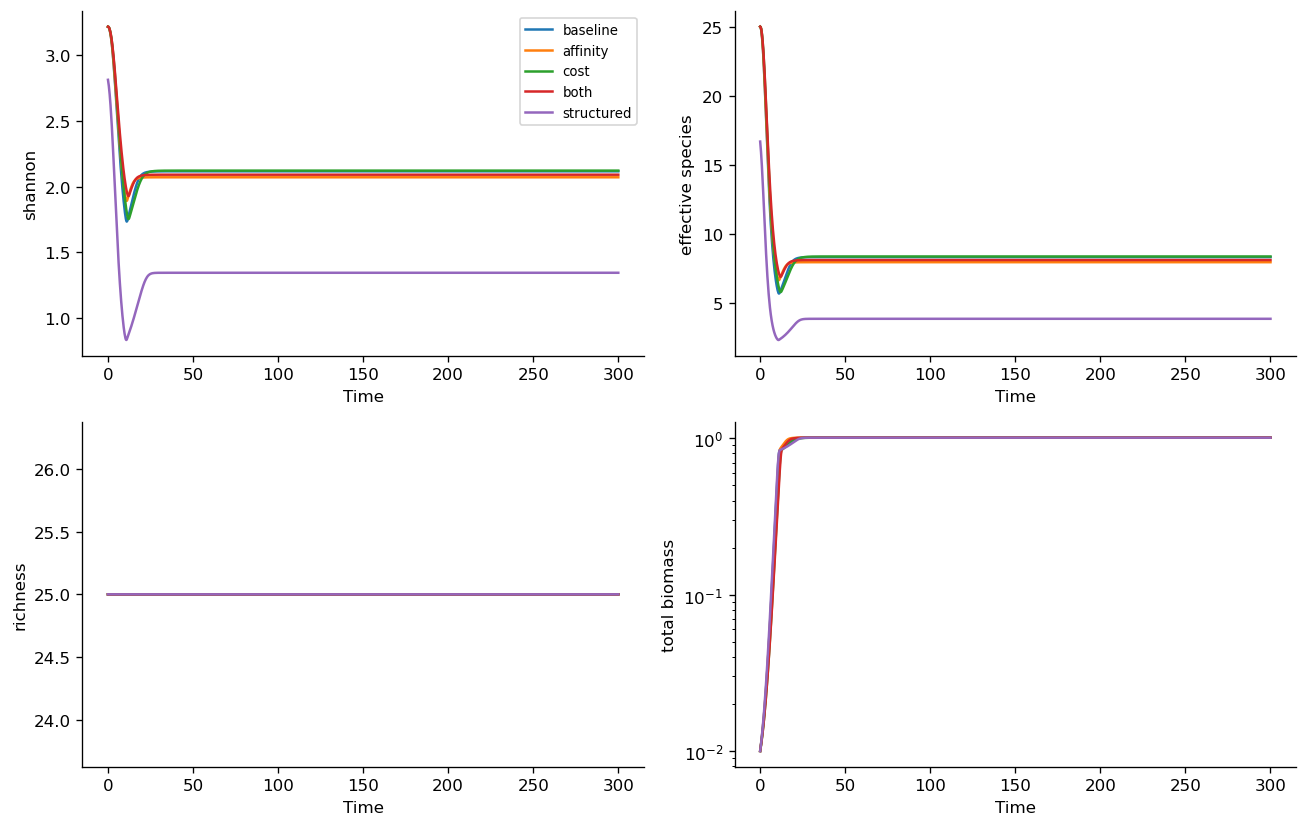

Figure 1. Shannon H (natural logarithm), effective diversity exp(H), species remaining above the cutoff, and total living biomass. The first four scenarios share intrinsic growth, resistance, food permissions, secretion and initial abundance draws; growth capacity differs when resistance cost is enabled. The structured scenario changes several traits jointly, so its difference cannot be attributed to one mechanism. Shannon is undefined when total biomass is zero.


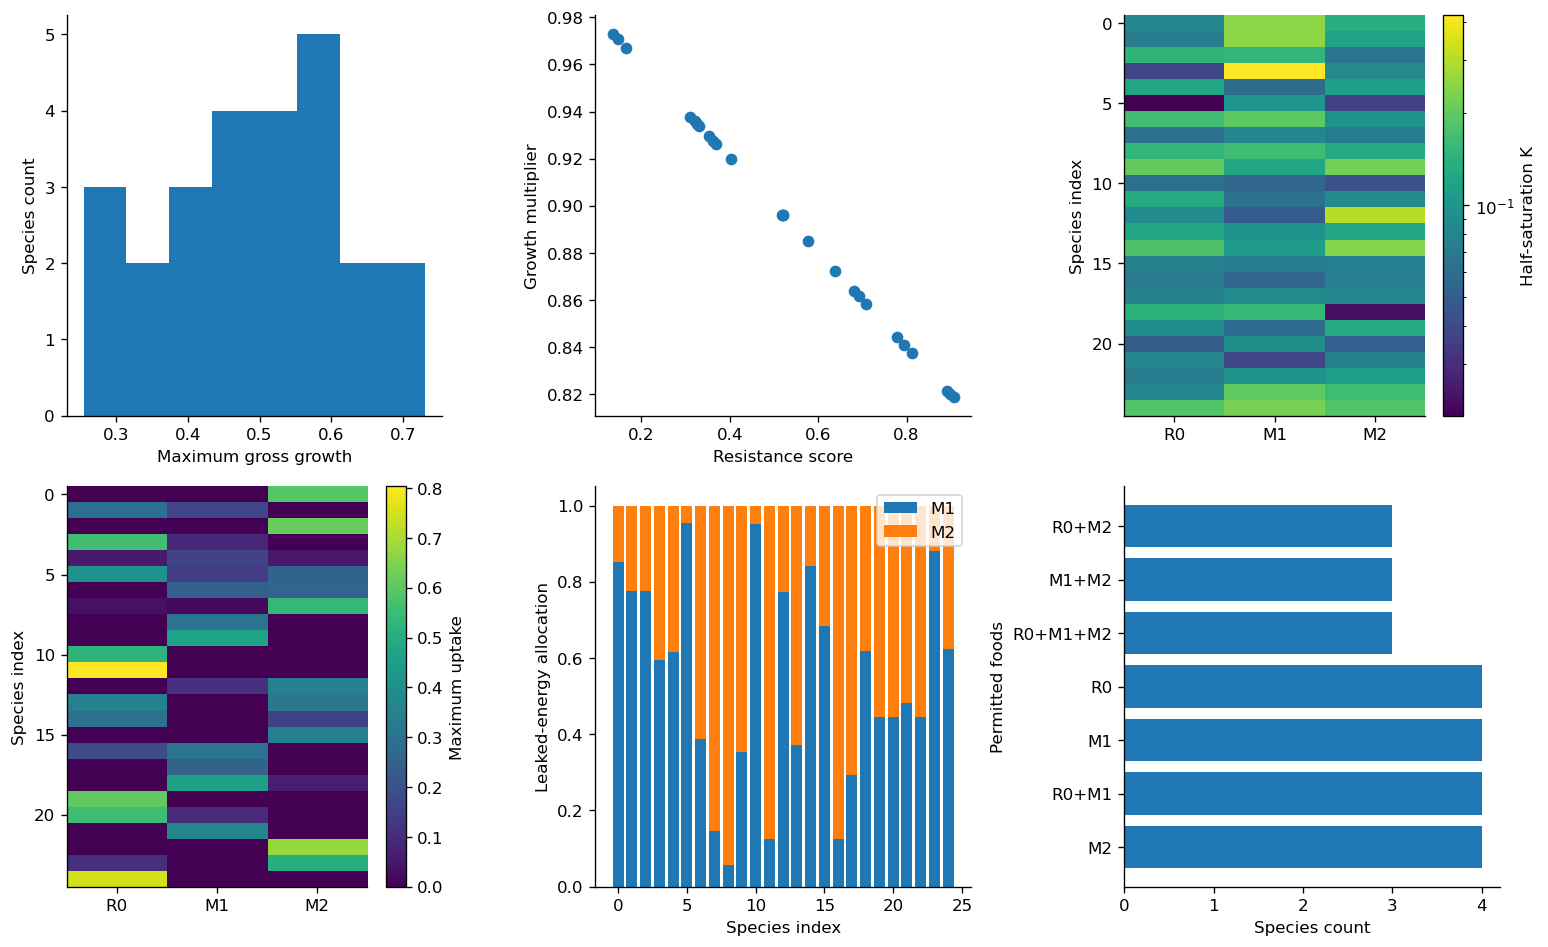

Figure 2. Realized traits in the both scenario. Lower K means uptake remains more efficient at low chemical concentration. Maximum uptake is zero for forbidden foods. Intrinsic growth, resistance and K use separate draws; resistance imposes a linear growth cost, which affects uptake capacity even without antibiotics. Secretion allocations describe potential output when R0 is actually consumed.


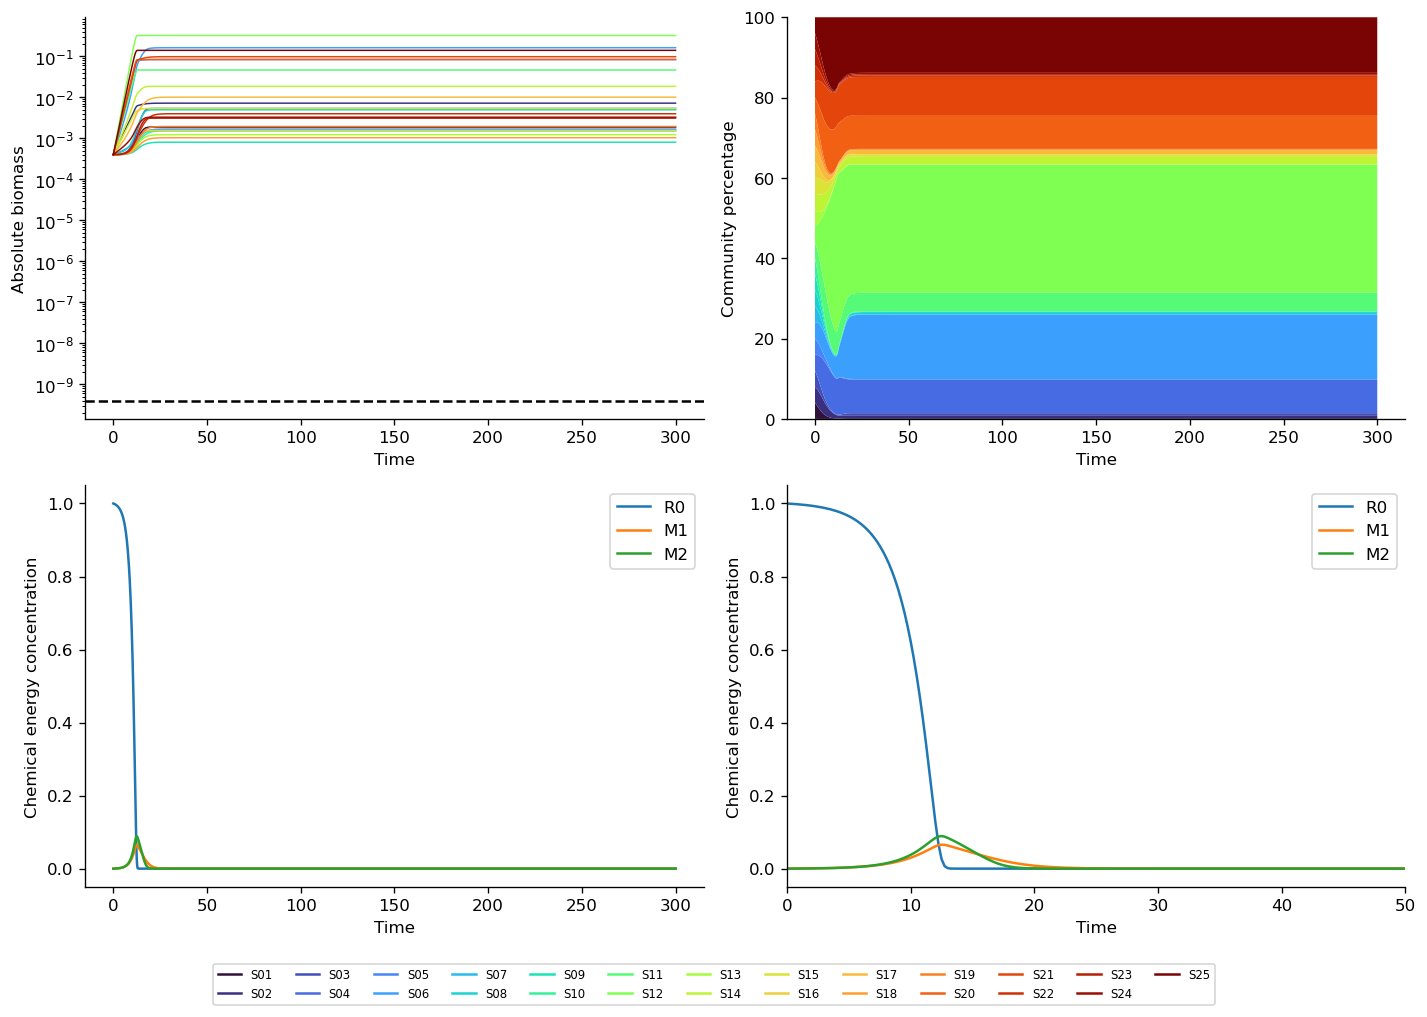

Figure 3 (both). Species biomass, composition, chemical depletion and an early-time chemical zoom. M1/M2 begin at zero and accumulate only through R0 consumption. Log plots show extinct species at a display floor, not positive simulated biomass. Percentages can rise while absolute biomass falls. Species colors are consistent across these panels.


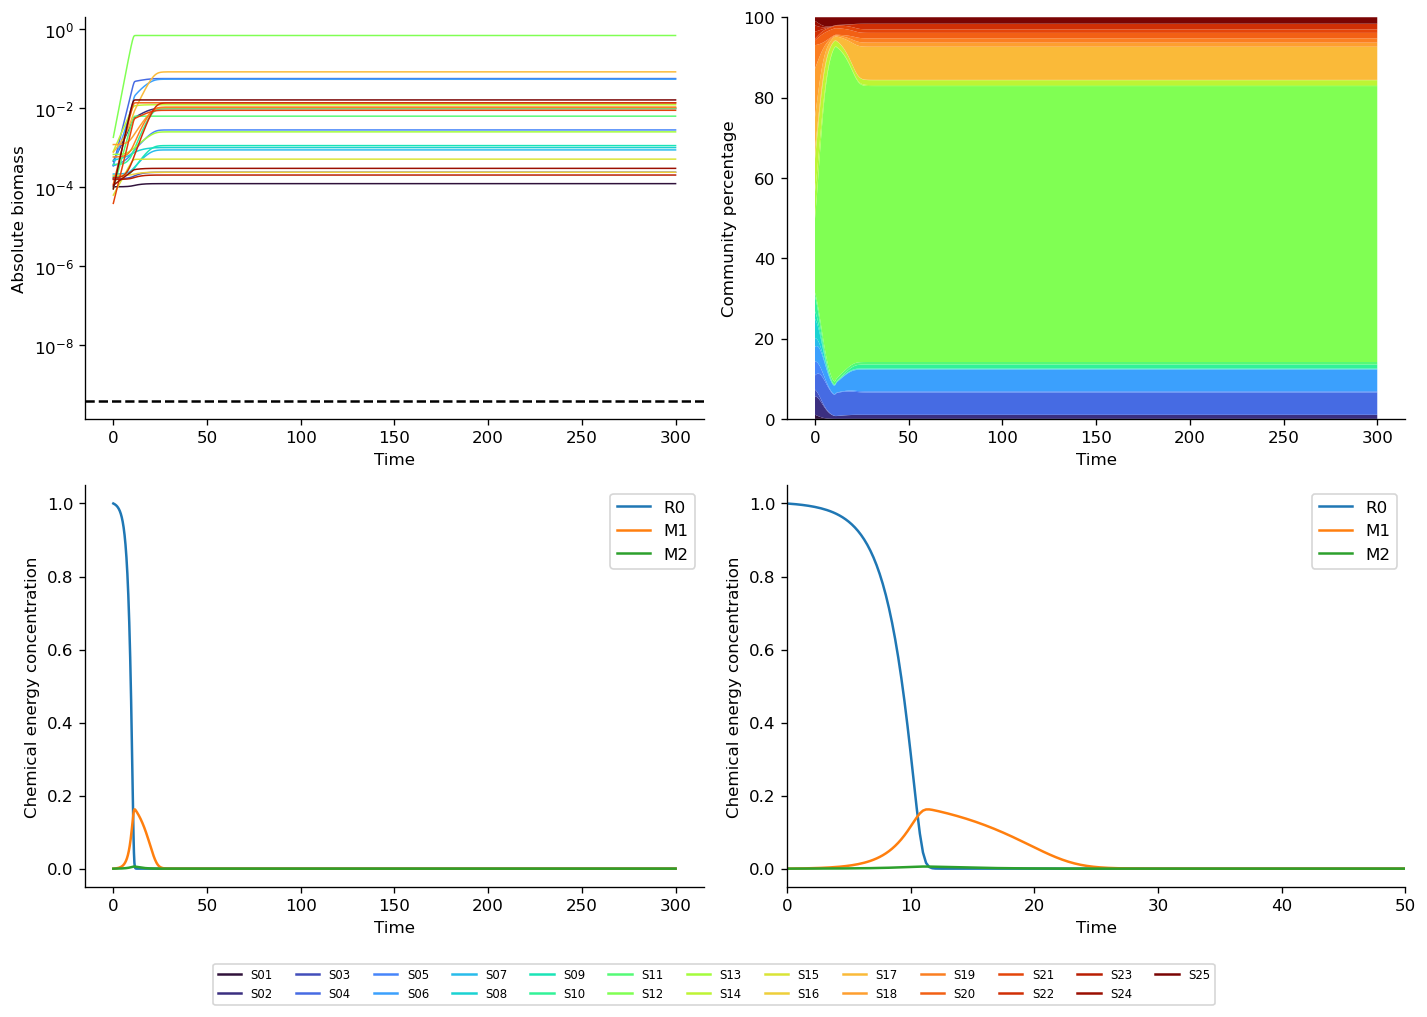

Figure 3 (structured). Species biomass, composition, chemical depletion and an early-time chemical zoom. M1/M2 begin at zero and accumulate only through R0 consumption. Log plots show extinct species at a display floor, not positive simulated biomass. Percentages can rise while absolute biomass falls. Species colors are consistent across these panels.


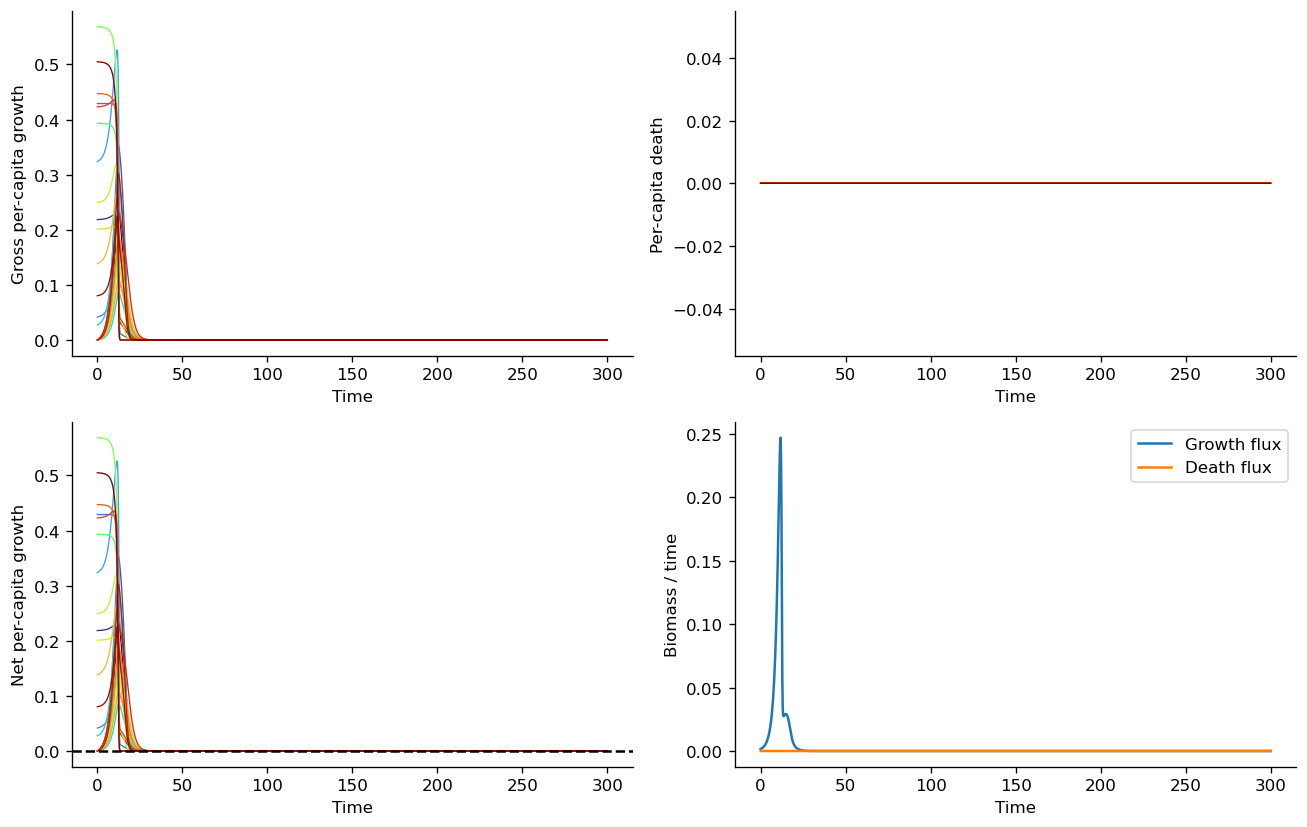

Figure 4. Resource-limited gross growth, zero mortality, net growth and community biomass fluxes in the both scenario. Mortality is zero: resource depletion causes growth to approach zero, not starvation death. No decline-driven extinctions are expected. Rates after irreversible removal are hidden.


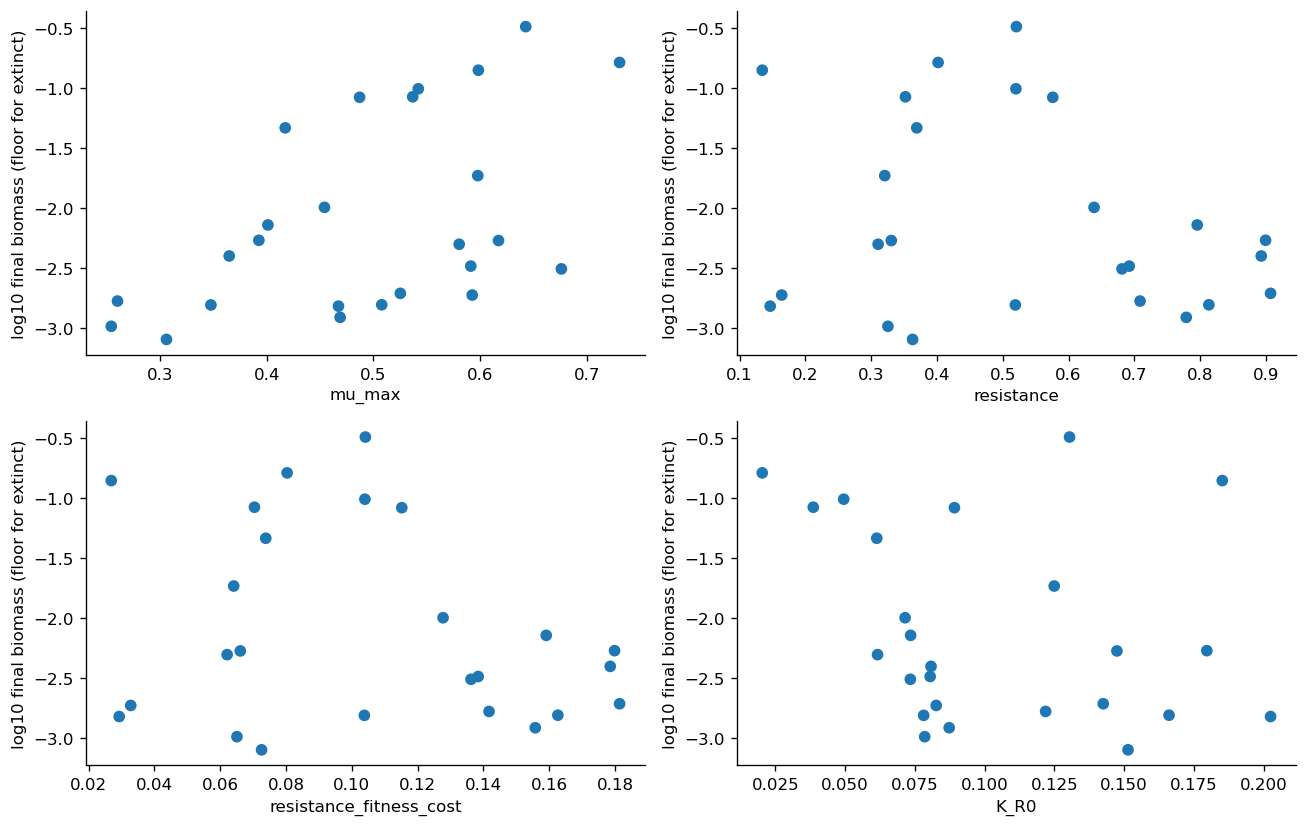

Figure 5. Single-community trait associations: blue species persist above the cutoff, red species were removed. Extinct final biomass is displayed at a floor. K_R0 has no uptake effect for species forbidden from using R0. These plots are descriptive; food permissions and interactions can confound apparent trait effects.


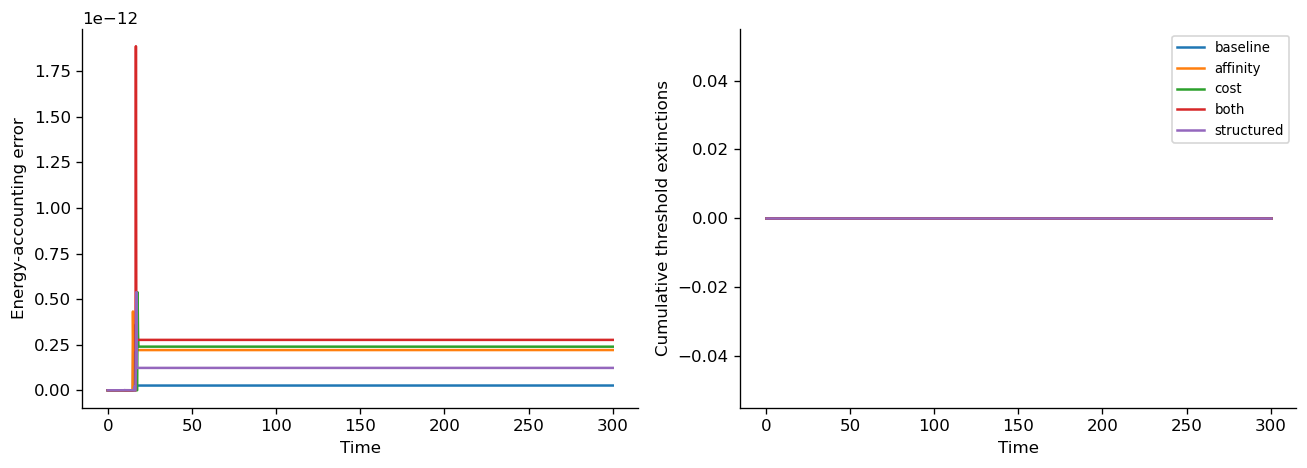

Figure 6. Accounting residuals and cumulative threshold extinctions. Energy-equivalent resources plus living biomass, accumulated mortality and cutoff losses remain equal to the initial total. The extinction curve records numerical cutoff crossings, not experimental viability measurements.


In [3]:
runs,scenario_summary=analysis_module.run_scenarios(config,out)
display(scenario_summary)
figures=analysis_module.make_figures(runs,out)
for path,caption in figures:
    display(Image(filename=str(path)))
    print(caption)


## Realized parameter distributions

In [4]:
for name,(p,r) in runs.items():
    print(name)
    display(p['table'].select_dtypes(include='number').describe().T)


baseline


,count,mean,std,min,25%,50%,75%,max
growth_score,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
intrinsic_mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
resistance_growth_multiplier,25.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000
resistance_fitness_cost,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
death_rate,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
total_uptake_capacity,25.0,0.601233,1.646217e-01,0.271924,0.546686,0.612674,0.711393,0.896778
M1_secretion_share,25.0,0.544626,2.710627e-01,0.056926,0.371568,0.596019,0.774623,0.955243
M2_secretion_share,25.0,0.455374,2.710627e-01,0.044757,0.225377,0.403981,0.628432,0.943074
initial_biomass,25.0,0.000400,0.000000e+00,0.000400,0.000400,0.000400,0.000400,0.000400


affinity


,count,mean,std,min,25%,50%,75%,max
growth_score,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
intrinsic_mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
resistance_growth_multiplier,25.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000
resistance_fitness_cost,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
death_rate,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
total_uptake_capacity,25.0,0.601233,1.646217e-01,0.271924,0.546686,0.612674,0.711393,0.896778
M1_secretion_share,25.0,0.544626,2.710627e-01,0.056926,0.371568,0.596019,0.774623,0.955243
M2_secretion_share,25.0,0.455374,2.710627e-01,0.044757,0.225377,0.403981,0.628432,0.943074
initial_biomass,25.0,0.000400,0.000000e+00,0.000400,0.000400,0.000400,0.000400,0.000400


cost


,count,mean,std,min,25%,50%,75%,max
growth_score,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
intrinsic_mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
mu_max,25.0,0.494384,1.280583e-01,0.254223,0.401075,0.507779,0.592565,0.730710
resistance_growth_multiplier,25.0,0.894718,4.881790e-02,0.818631,0.858297,0.896016,0.933886,0.973096
resistance_fitness_cost,25.0,0.105282,4.881790e-02,0.026904,0.066114,0.103984,0.141703,0.181369
death_rate,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
total_uptake_capacity,25.0,0.538671,1.544231e-01,0.254223,0.459719,0.525202,0.648189,0.813276
M1_secretion_share,25.0,0.544626,2.710627e-01,0.056926,0.371568,0.596019,0.774623,0.955243
M2_secretion_share,25.0,0.455374,2.710627e-01,0.044757,0.225377,0.403981,0.628432,0.943074
initial_biomass,25.0,0.000400,0.000000e+00,0.000400,0.000400,0.000400,0.000400,0.000400


both


,count,mean,std,min,25%,50%,75%,max
growth_score,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
intrinsic_mu_max,25.0,0.552315,1.382925e-01,0.271924,0.476948,0.577454,0.638731,0.794546
mu_max,25.0,0.494384,1.280583e-01,0.254223,0.401075,0.507779,0.592565,0.730710
resistance_growth_multiplier,25.0,0.894718,4.881790e-02,0.818631,0.858297,0.896016,0.933886,0.973096
resistance_fitness_cost,25.0,0.105282,4.881790e-02,0.026904,0.066114,0.103984,0.141703,0.181369
death_rate,25.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
total_uptake_capacity,25.0,0.538671,1.544231e-01,0.254223,0.459719,0.525202,0.648189,0.813276
M1_secretion_share,25.0,0.544626,2.710627e-01,0.056926,0.371568,0.596019,0.774623,0.955243
M2_secretion_share,25.0,0.455374,2.710627e-01,0.044757,0.225377,0.403981,0.628432,0.943074
initial_biomass,25.0,0.000400,0.000000e+00,0.000400,0.000400,0.000400,0.000400,0.000400


structured


,count,mean,std,min,25%,50%,75%,max
growth_score,25.0,0.552315,0.138293,0.271924,0.476948,0.577454,0.638731,0.794546
intrinsic_mu_max,25.0,0.552315,0.138293,0.271924,0.476948,0.577454,0.638731,0.794546
mu_max,25.0,0.494384,0.128058,0.254223,0.401075,0.507779,0.592565,0.730710
resistance_growth_multiplier,25.0,0.894718,0.048818,0.818631,0.858297,0.896016,0.933886,0.973096
resistance_fitness_cost,25.0,0.105282,0.048818,0.026904,0.066114,0.103984,0.141703,0.181369
death_rate,25.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
total_uptake_capacity,25.0,0.520733,0.151577,0.254223,0.451928,0.507779,0.612931,0.813276
M1_secretion_share,25.0,0.663045,0.371137,0.000000,0.365895,0.839824,1.000000,1.000000
M2_secretion_share,25.0,0.336955,0.371137,0.000000,0.000000,0.160176,0.634105,1.000000
initial_biomass,25.0,0.000400,0.000415,0.000039,0.000120,0.000216,0.000481,0.001839


## Cutoff sensitivity

With no mortality, no decline-driven cutoff extinctions are expected. This check preserves the original cutoff analysis.

In [5]:
rows=[]
for f in [1e-4,1e-6,1e-8]:
    p=model_module.generate(replace(config,extinction_fraction=f))
    r=model_module.simulate(p)
    rows.append({'cutoff_fraction':f,'survivors':int(np.isnan(r['extinction']).sum()),'final_biomass':r['N'][-1].sum()})
display(pd.DataFrame(rows))
pd.DataFrame(rows).to_csv(out/'cutoff_sensitivity.csv',index=False)


,cutoff_fraction,survivors,final_biomass
0,1.000000e-04,25,1.01
1,1.000000e-06,25,1.01
2,1.000000e-08,25,1.01


## Ten matched random communities

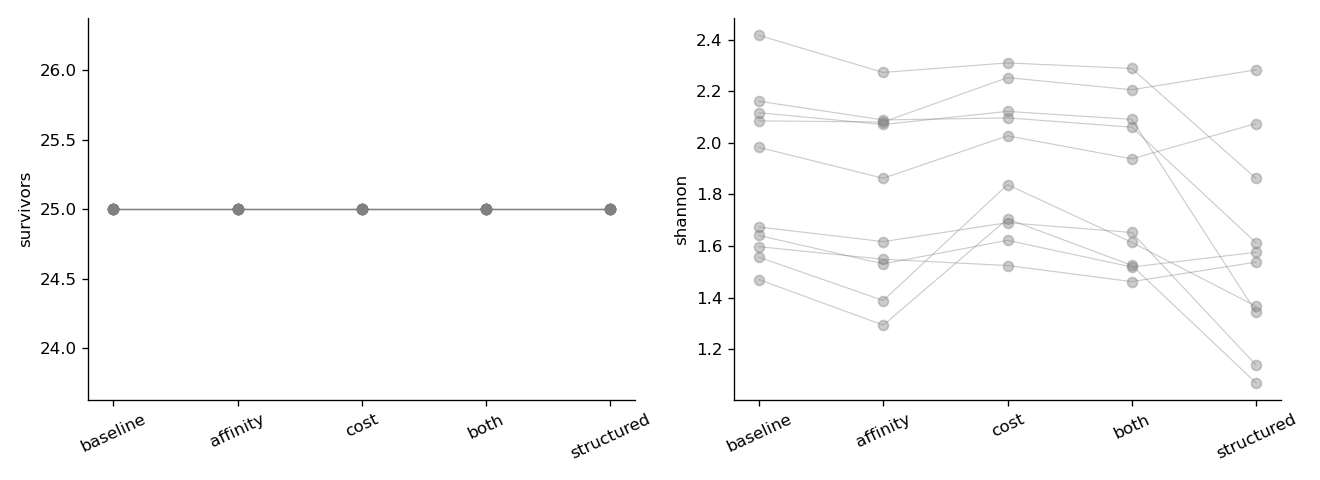

Figure 7. Matched scenario comparisons over the requested random communities. Each gray line connects conditions using one seed. Species counts and final Shannon need not move together: losing rare species may change richness more than Shannon. The structured condition changes several assumptions together. Lines summarize simulations, not biological confidence intervals.


In [6]:
repeated=analysis_module.repeated_scenarios(config,replicates=10)
repeated.to_csv(out/'repeated_species_summary.csv',index=False)
path,caption=analysis_module.repeated_plot(repeated,out)
display(Image(filename=str(path)));print(caption)


## Starting composition: equal, fast/slow enriched and ten random mixtures

Species traits and total starting biomass are fixed. Trait enrichment now shows growth, resistance and resistance cost, instead of zero mortality traits.

                    initial_Shannon  final_Shannon  survivors  final_total_biomass  initial_weighted_growth  final_weighted_growth  initial_weighted_resistance  final_weighted_resistance  initial_weighted_resistance_cost  final_weighted_resistance_cost
starting_community                                                                                                                                                                                                                                          
Equal                        3.2189         2.0909         25                 1.01                   0.4944                 0.5989                       0.5264                     0.4339                            0.1053                          0.0868
Fast enriched                2.5118         1.4802         25                 1.01                   0.6304                 0.6544                       0.4604                     0.4285                            0.0921                     

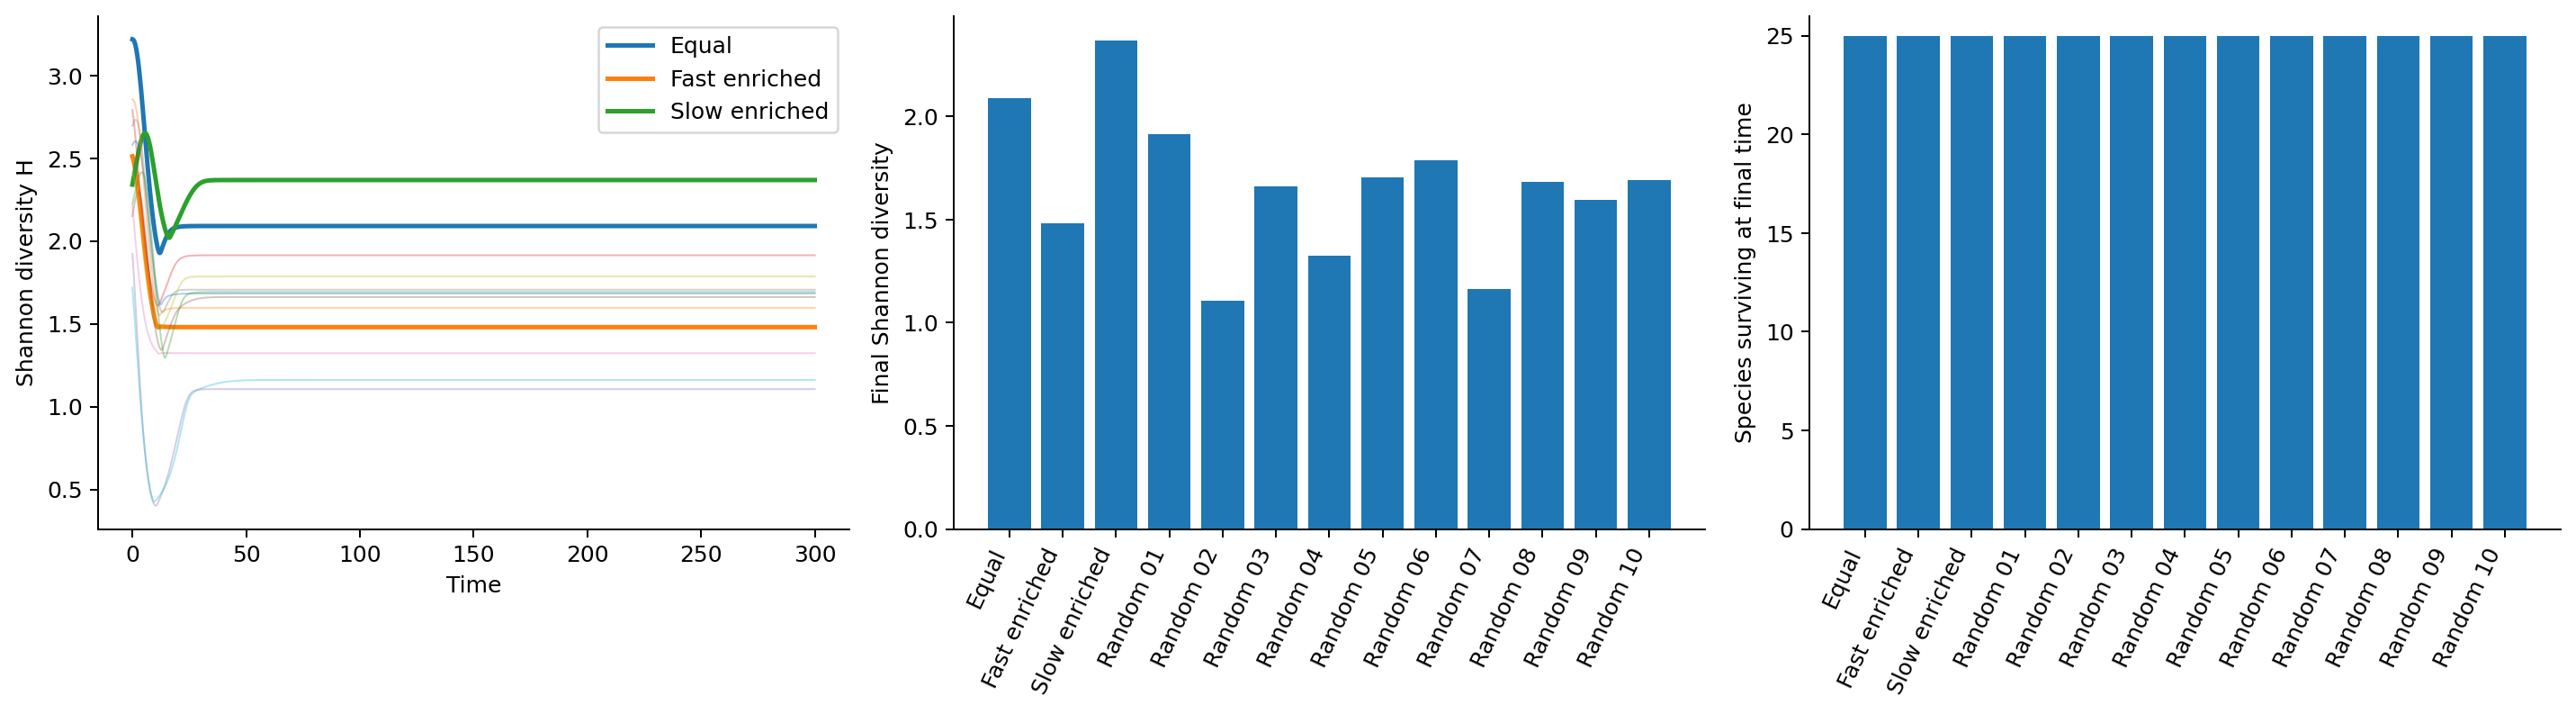

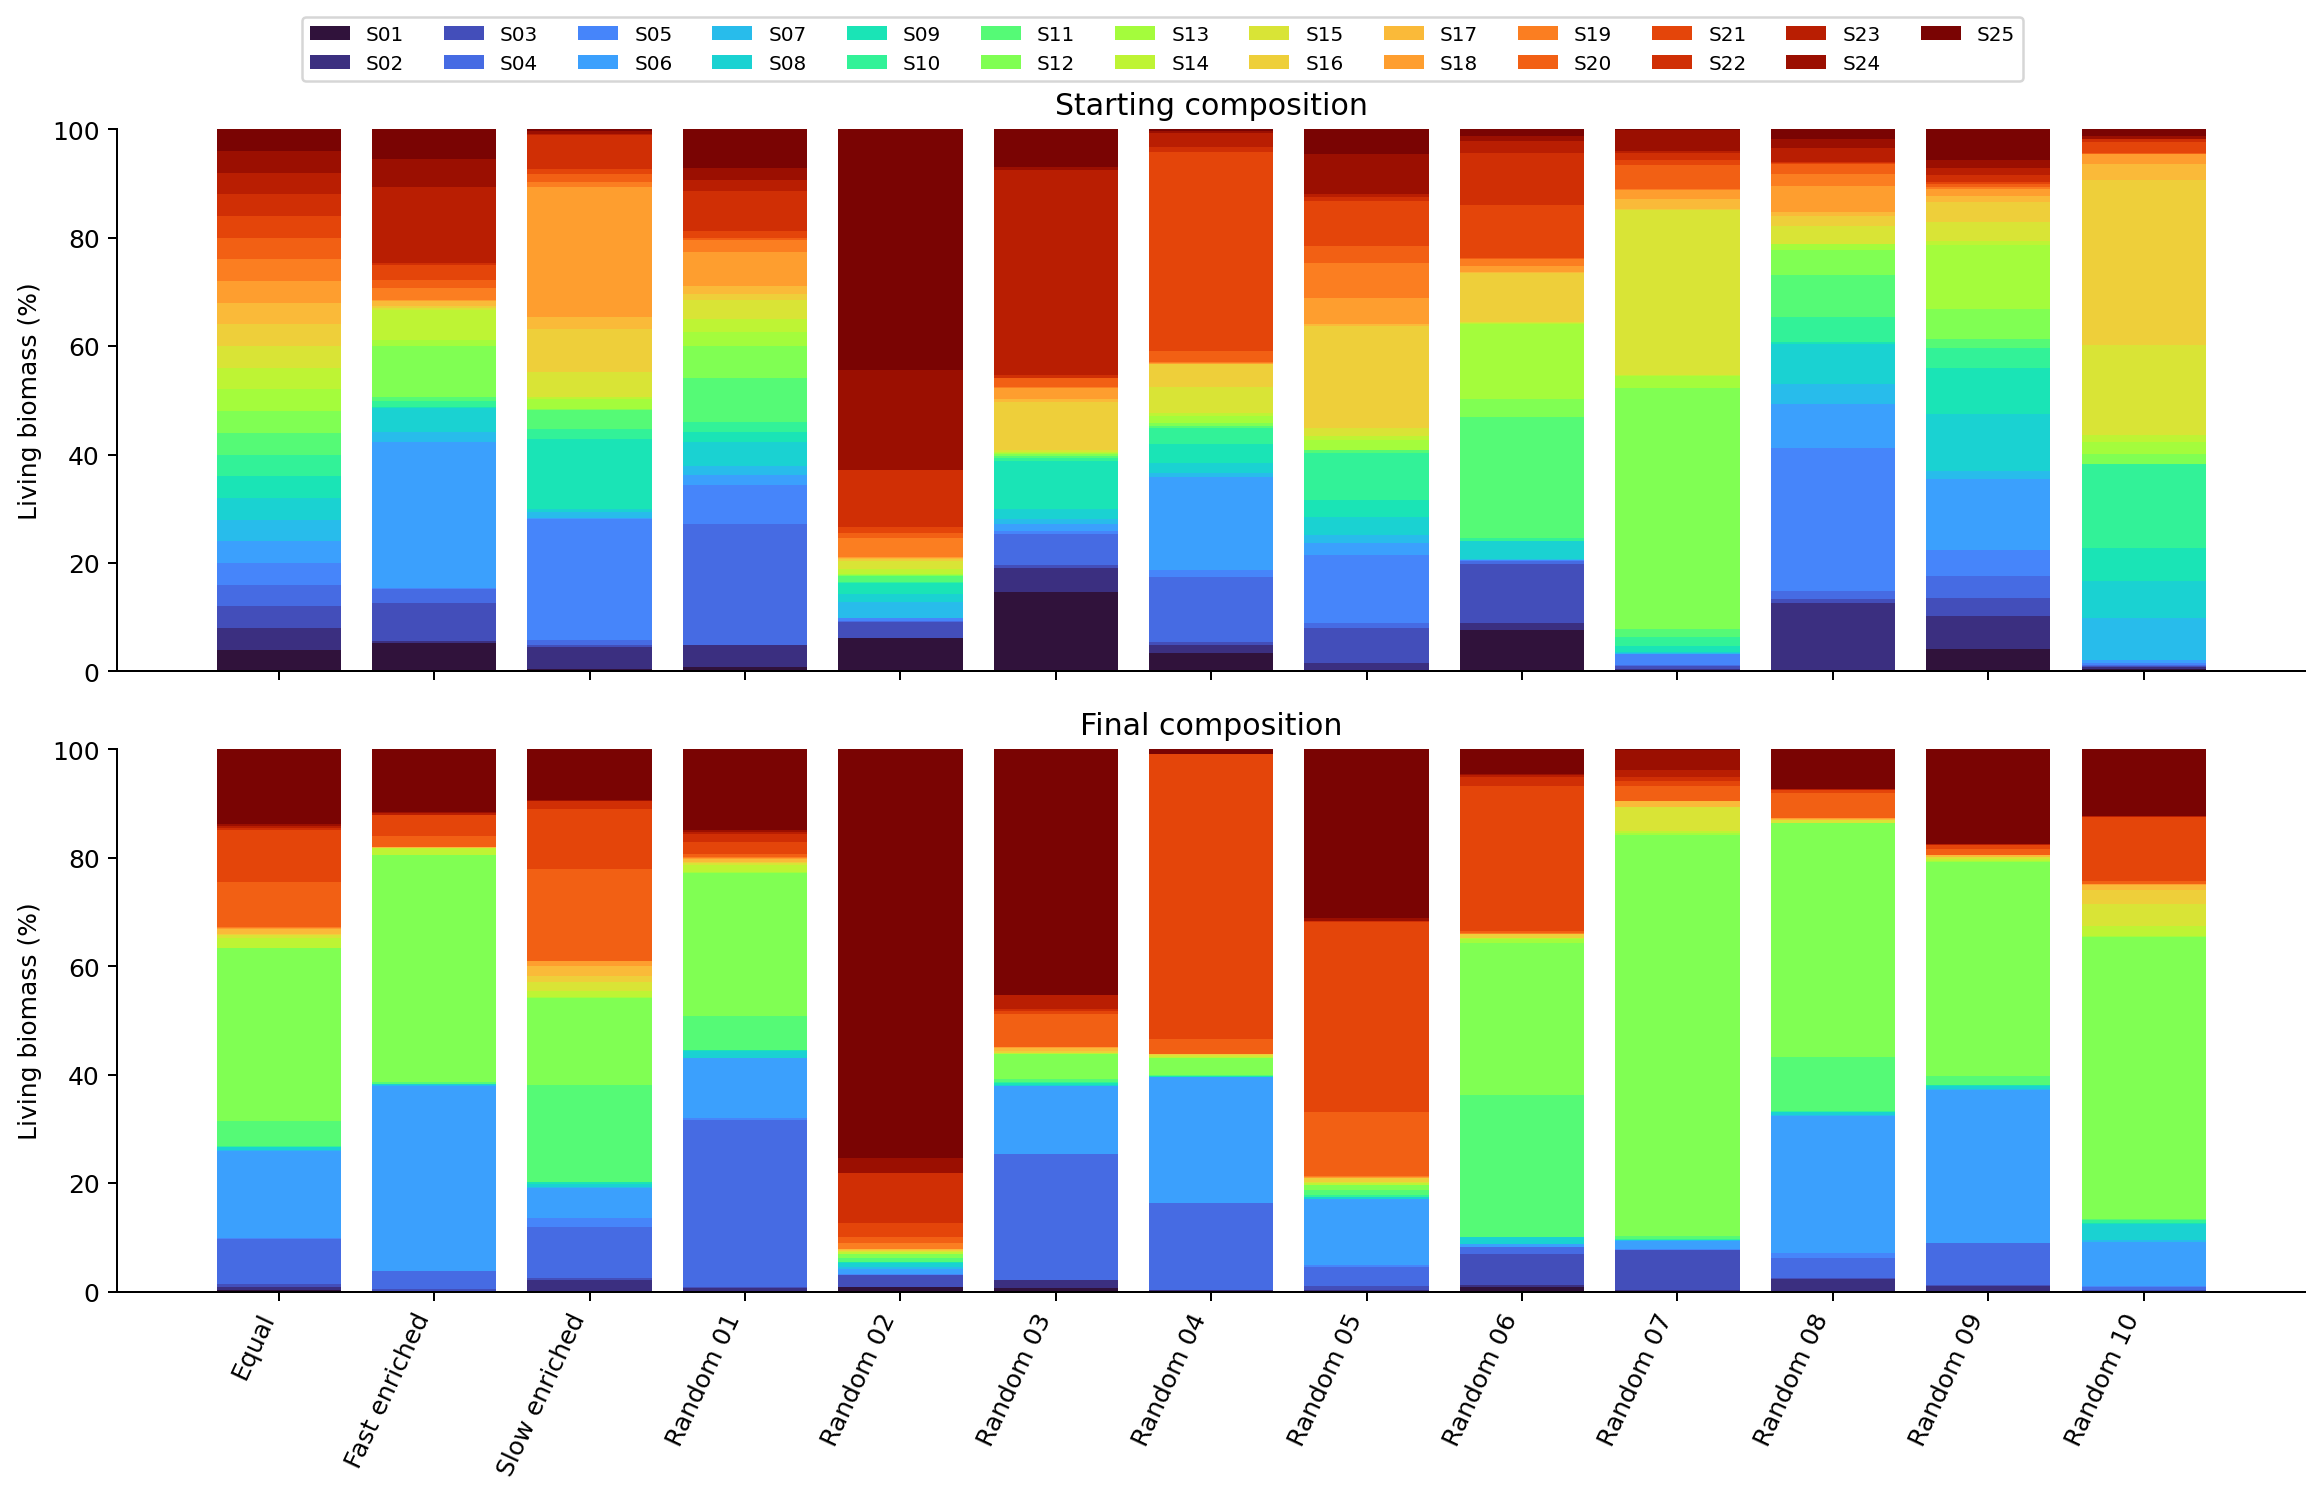

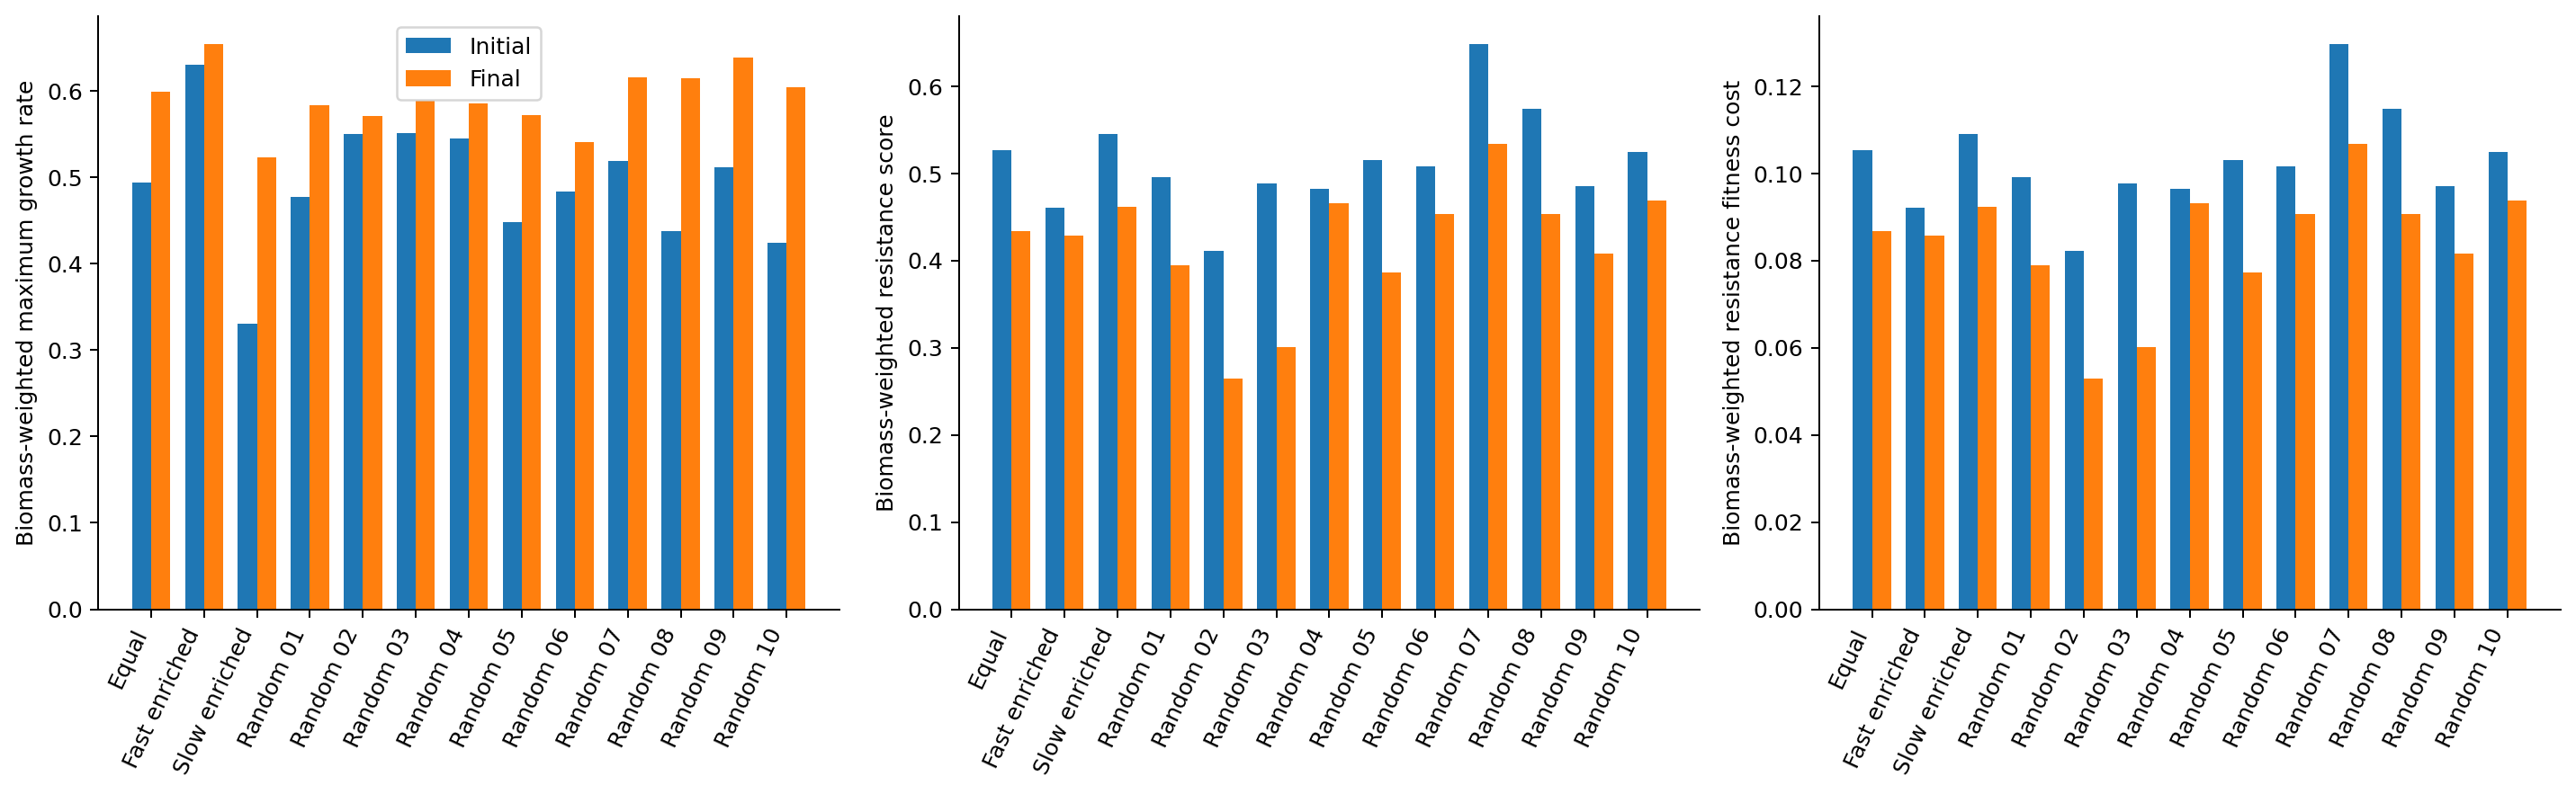

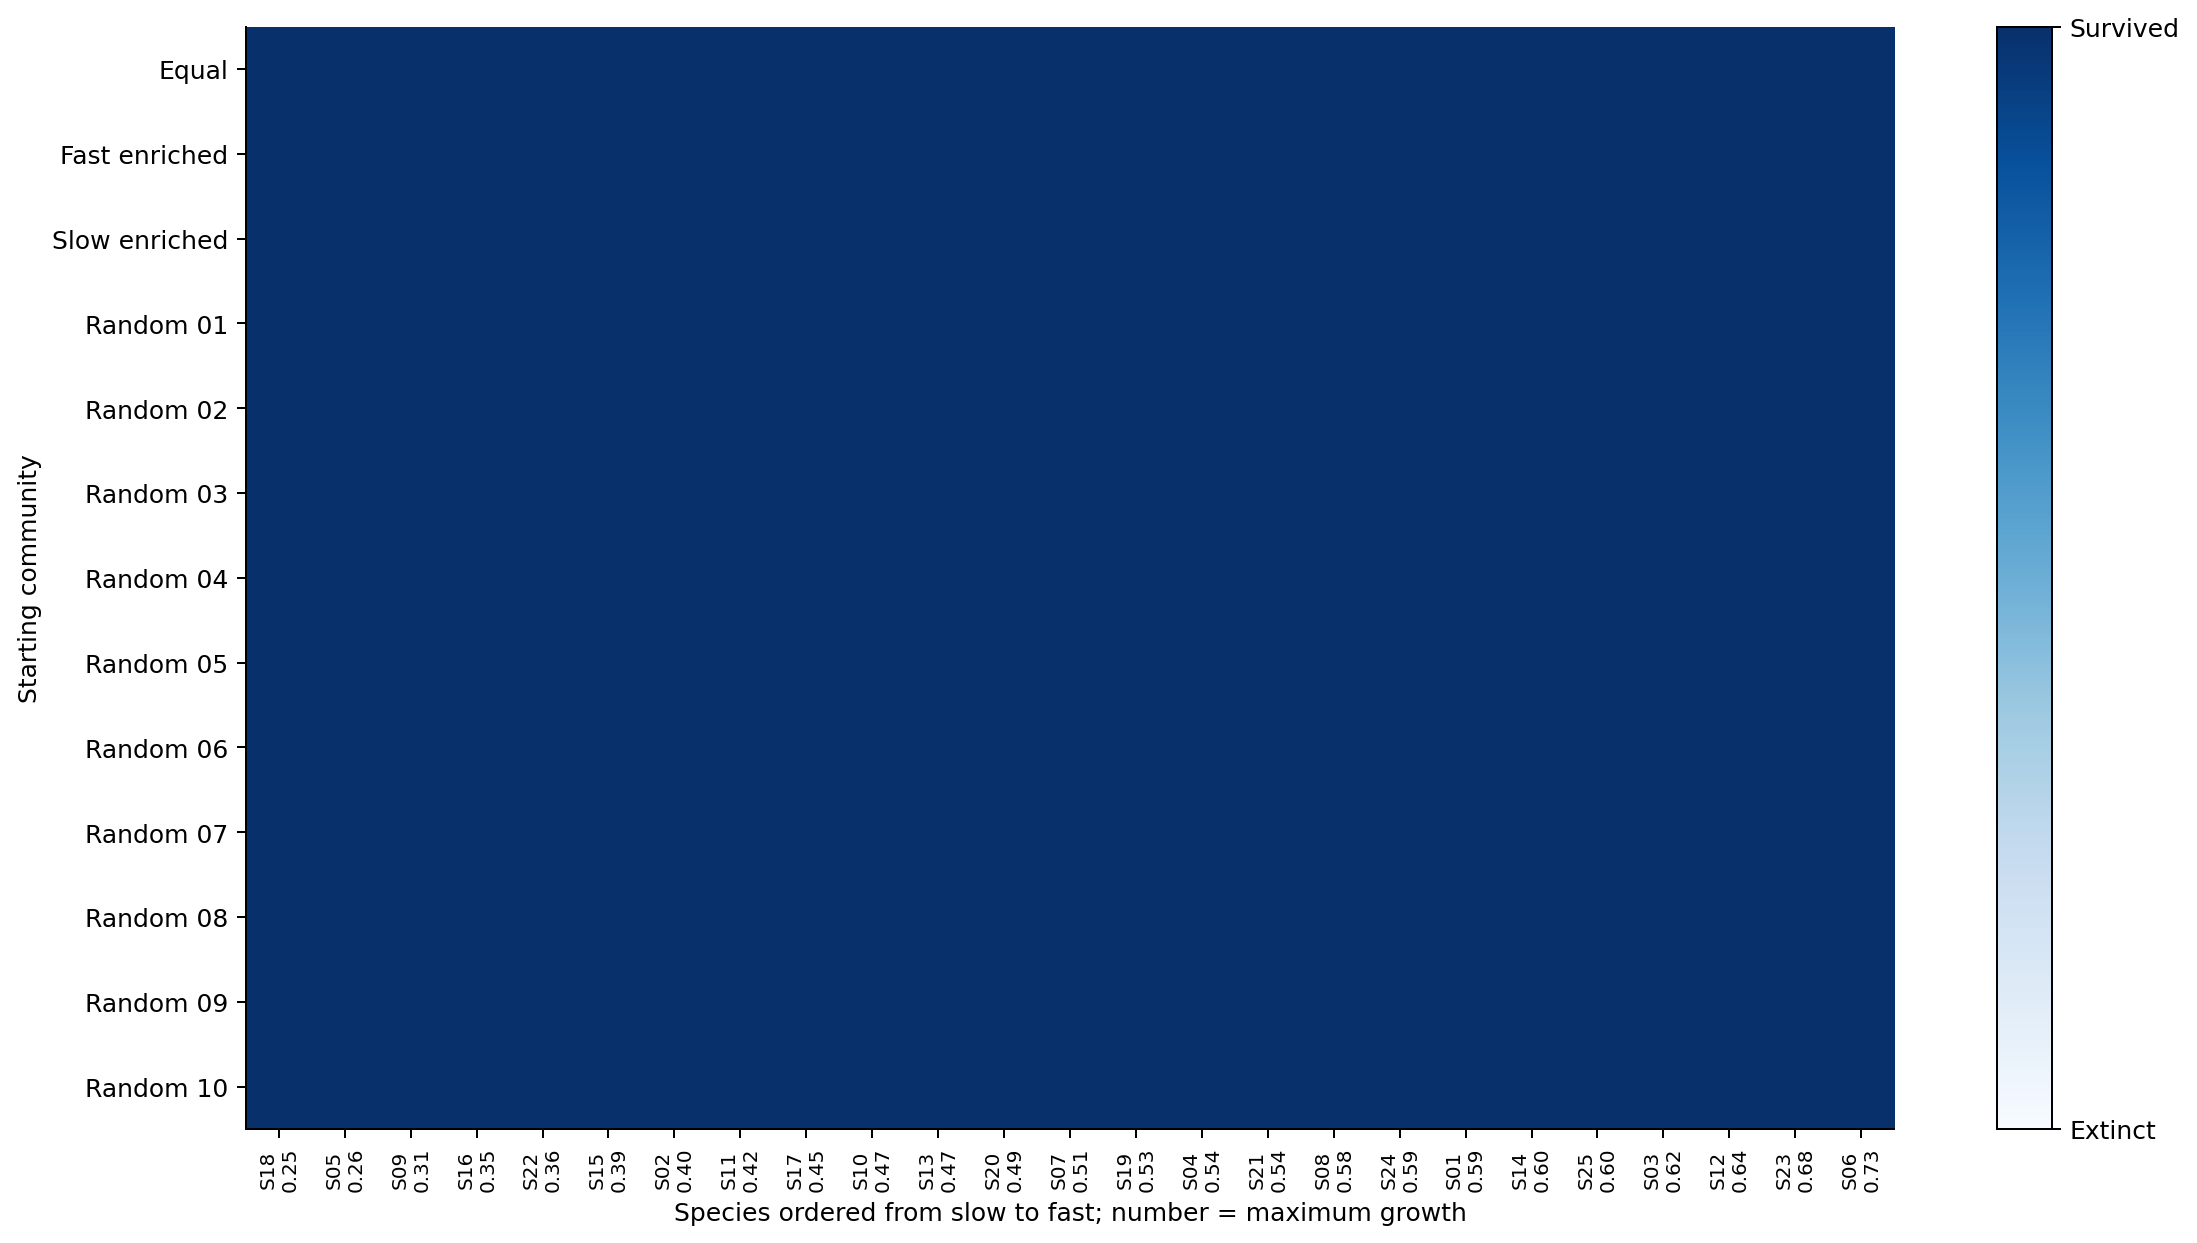

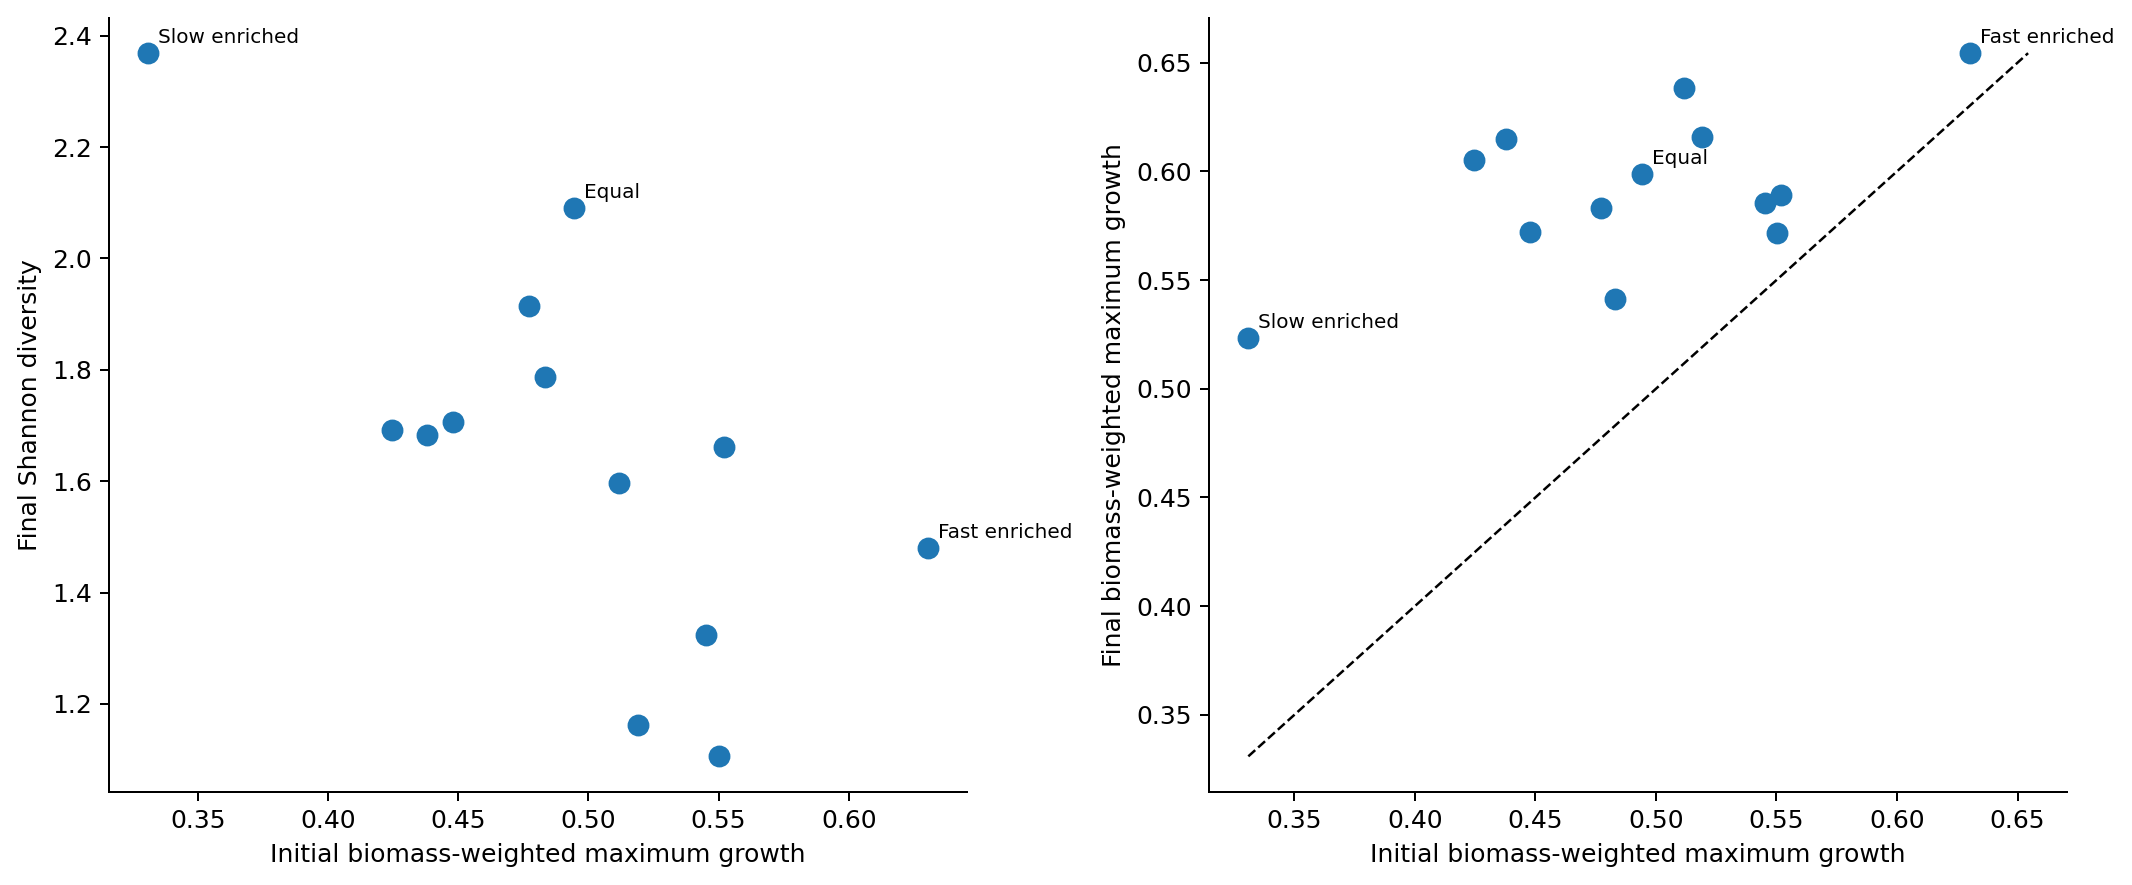

In [7]:
composition_source = '"""Matched initial-composition experiment: equal, fast/slow enriched, ten random mixtures."""\nfrom pathlib import Path\nfrom dataclasses import replace\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport model as model_module\nimport analysis_tools as analysis_module\nfrom model import Config\ndef display(x):\n    print(x.to_string() if hasattr(x,"to_string") else x)\ndef run(config=Config(),output=\'initial_composition_experiment\'):\n    # Use the aligned "both" model: variable affinity + resistance growth cost.\n    both_config = replace(\n        config,\n        variable_affinity=True,\n        resistance_cost_max=.20,\n        structured_community=False,\n    )\n    \n    template = model_module.generate(both_config)\n    traits = template["table"].copy()\n    species = traits["species"].to_numpy()\n    growth = traits["mu_max"].to_numpy()\n    n = len(species)\n    total_initial_biomass = both_config.initial_biomass\n    \n    # Starting percentages:\n    # Equal = 4% each for 25 species.\n    # Growth-biased communities retain every species, but favor fast/slow growers.\n    # Random communities use different lognormal abundance mixtures.\n    rng = np.random.default_rng(2026)\n    growth_standardized = (\n        (growth - growth.mean()) / max(growth.std(), 1e-12)\n    )\n    \n    starting_shares = {\n        "Equal": np.ones(n),\n        "Fast enriched": np.exp(1.5 * growth_standardized),\n        "Slow enriched": np.exp(-1.5 * growth_standardized),\n    }\n    \n    for k in range(10):\n        starting_shares[f"Random {k + 1:02d}"] = rng.lognormal(\n            mean=0, sigma=1.5, size=n\n        )\n    \n    starting_shares = {\n        name: weights / weights.sum()\n        for name, weights in starting_shares.items()\n    }\n    \n    results = {}\n    summary_rows = []\n    species_rows = []\n    \n    for name, shares in starting_shares.items():\n        # Same seed gives exactly the same traits in every experiment.\n        community = model_module.generate(both_config)\n    \n        # Only change initial biomass allocation.\n        initial = total_initial_biomass * shares\n        community["initial"] = initial.copy()\n        community["table"]["initial_biomass"] = initial\n    \n        result = model_module.simulate(community)\n        diversity = analysis_module.diversity(result)\n    \n        final = result["N"][-1]\n        final_total = final.sum()\n        final_shares = (\n            final / final_total\n            if final_total > 0\n            else np.full(n, np.nan)\n        )\n        survived = np.isnan(result["extinction"])\n    \n        results[name] = {\n            "initial_shares": shares,\n            "final_shares": final_shares,\n            "survived": survived,\n            "simulation": result,\n            "diversity": diversity,\n        }\n    \n        summary_rows.append({\n            "starting_community": name,\n            "initial_Shannon": diversity["shannon"].iloc[0],\n            "final_Shannon": diversity["shannon"].iloc[-1],\n            "survivors": int(survived.sum()),\n            "final_total_biomass": final_total,\n            "initial_weighted_growth": shares @ growth,\n            "final_weighted_growth": (\n                final_shares @ growth if final_total > 0 else np.nan\n            ),\n            "initial_weighted_resistance":\n                shares @ traits["resistance"].to_numpy(),\n            "final_weighted_resistance": (\n                final_shares @ traits["resistance"].to_numpy()\n                if final_total > 0 else np.nan\n            ),\n            "initial_weighted_resistance_cost":\n                shares @ traits["resistance_fitness_cost"].to_numpy(),\n            "final_weighted_resistance_cost": (\n                final_shares @ traits["resistance_fitness_cost"].to_numpy()\n                if final_total > 0 else np.nan\n            ),\n        })\n    \n        species_table = traits.copy()\n        species_table["starting_community"] = name\n        species_table["initial_percent"] = 100 * shares\n        species_table["final_percent"] = 100 * final_shares\n        species_table["final_biomass"] = final\n        species_table["survived"] = survived\n        species_table["extinction_time"] = result["extinction"]\n        species_rows.append(species_table)\n    \n    summary = pd.DataFrame(summary_rows).set_index("starting_community")\n    species_outcomes = pd.concat(species_rows, ignore_index=True)\n    \n    display(summary.round(4))\n    \n    # Save tables and figures.\n    save_folder = Path(output)\n    save_folder.mkdir(exist_ok=True,parents=True)\n    summary.to_csv(save_folder / "community_summary.csv")\n    species_outcomes.to_csv(\n        save_folder / "species_traits_and_outcomes.csv", index=False\n    )\n    \n    def caption(text):\n        print("\\n" + text + "\\n")\n    \n    def finish_figure(fig, filename):\n        fig.tight_layout()\n        fig.savefig(save_folder / filename, dpi=180, bbox_inches="tight")\n        plt.close(fig)\n    \n    names = list(results)\n    x = np.arange(len(names))\n    \n    # 1. Shannon trajectories and final outcomes.\n    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))\n    \n    for name in names:\n        d = results[name]["diversity"]\n        highlighted = name in ["Equal", "Fast enriched", "Slow enriched"]\n        axes[0].plot(\n            d["time"], d["shannon"],\n            linewidth=2 if highlighted else 0.8,\n            alpha=1 if highlighted else 0.35,\n            label=name if highlighted else None,\n        )\n    \n    axes[0].set(xlabel="Time", ylabel="Shannon diversity H")\n    axes[0].legend()\n    \n    axes[1].bar(x, summary["final_Shannon"])\n    axes[1].set(ylabel="Final Shannon diversity")\n    \n    axes[2].bar(x, summary["survivors"])\n    axes[2].set(ylabel="Species surviving at final time", ylim=(0, n + 1))\n    \n    for ax in axes[1:]:\n        ax.set_xticks(x)\n        ax.set_xticklabels(names, rotation=65, ha="right")\n    \n    finish_figure(fig, "01_shannon_and_survival.png")\n    caption(\n        "Figure 1. Starting proportions can alter Shannon diversity and final composition; zero mortality preserves species. "\n        "All experiments use identical traits, total starting biomass, and food. "\n        "Unequal communities already have lower initial Shannon, so interpret "\n        "the trajectories together with their starting values."\n    )\n    \n    # 2. Starting and final community composition.\n    initial_matrix = np.array([\n        results[name]["initial_shares"] for name in names\n    ])\n    final_matrix = np.array([\n        results[name]["final_shares"] for name in names\n    ])\n    \n    colors = plt.cm.turbo(np.linspace(0, 1, n))\n    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)\n    \n    for ax, matrix, title in zip(\n        axes,\n        [initial_matrix, final_matrix],\n        ["Starting composition", "Final composition"],\n    ):\n        bottom = np.zeros(len(names))\n        for i in range(n):\n            values = 100 * matrix[:, i]\n            ax.bar(x, values, bottom=bottom, color=colors[i],\n                   label=species[i])\n            bottom += np.nan_to_num(values)\n        ax.set(title=title, ylabel="Living biomass (%)", ylim=(0, 100))\n    \n    axes[1].set_xticks(x)\n    axes[1].set_xticklabels(names, rotation=65, ha="right")\n    fig.legend(\n        handles=axes[0].get_legend_handles_labels()[0],\n        labels=species.tolist(),\n        loc="upper center", bbox_to_anchor=(0.5, 1.04),\n        ncol=13, fontsize=8,\n    )\n    finish_figure(fig, "02_initial_final_composition.png")\n    caption(\n        "Figure 2. Each color represents the same species in both panels. "\n        "Compare which starting mixtures lead to different final dominants. "\n        "Percentages describe the remaining living biomass, not its absolute "\n        "amount; dominance reflects relative growth, not mortality in this control."\n    )\n    \n    # 3. Biomass-weighted community traits.\n    trait_columns = [\n        ("growth", "Maximum growth rate"),\n        ("resistance", "Resistance score"),\n        ("resistance_cost", "Resistance fitness cost"),\n    ]\n    fig, axes = plt.subplots(1, 3, figsize=(16, 5))\n    \n    for ax, (column, label) in zip(axes, trait_columns):\n        ax.bar(\n            x - 0.18, summary[f"initial_weighted_{column}"],\n            width=0.36, label="Initial",\n        )\n        ax.bar(\n            x + 0.18, summary[f"final_weighted_{column}"],\n            width=0.36, label="Final",\n        )\n        ax.set(ylabel=f"Biomass-weighted {label.lower()}")\n        ax.set_xticks(x)\n        ax.set_xticklabels(names, rotation=65, ha="right")\n    \n    axes[0].legend()\n    finish_figure(fig, "03_community_trait_enrichment.png")\n    caption(\n        "Figure 3. Community traits are weighted by species\' biomass shares. "\n        "A higher final weighted growth capacity indicates enrichment in fast "\n        "growers, even if food depletion prevents them from growing at that "\n        "rate. Resistance scores and growth costs are fixed traits; "\n        "enrichment reflects resource competition without antibiotic killing."\n    )\n    \n    # 4. Which species survived? Order species by growth capacity.\n    order = np.argsort(growth)\n    survival_matrix = np.array([\n        results[name]["survived"] for name in names\n    ], dtype=int)[:, order]\n    \n    fig, ax = plt.subplots(figsize=(13, 7))\n    image = ax.imshow(\n        survival_matrix, aspect="auto", cmap="Blues", vmin=0, vmax=1\n    )\n    ax.set_xticks(np.arange(n))\n    ax.set_xticklabels(\n        [f"{species[i]}\\n{growth[i]:.2f}" for i in order],\n        rotation=90, fontsize=8,\n    )\n    ax.set_yticks(x)\n    ax.set_yticklabels(names)\n    ax.set(\n        xlabel="Species ordered from slow to fast; number = maximum growth",\n        ylabel="Starting community",\n    )\n    bar = fig.colorbar(image, ax=ax, ticks=[0, 1])\n    bar.ax.set_yticklabels(["Extinct", "Survived"])\n    finish_figure(fig, "04_species_survival.png")\n    caption(\n        "Figure 4. Dark cells indicate species above the extinction cutoff "\n        "at the final time. Species are ordered by maximum growth capacity. "\n        "All species persist in this mortality-free control; "\n        "the panel is a consistency check rather than evidence of killing."\n    )\n    \n    # 5. Are fast or slow growers enriched overall?\n    fig, axes = plt.subplots(1, 2, figsize=(12, 5))\n    \n    axes[0].scatter(\n        summary["initial_weighted_growth"],\n        summary["final_Shannon"], s=60,\n    )\n    axes[0].set(\n        xlabel="Initial biomass-weighted maximum growth",\n        ylabel="Final Shannon diversity",\n    )\n    \n    axes[1].scatter(\n        summary["initial_weighted_growth"],\n        summary["final_weighted_growth"], s=60,\n    )\n    low = min(\n        summary["initial_weighted_growth"].min(),\n        summary["final_weighted_growth"].min(),\n    )\n    high = max(\n        summary["initial_weighted_growth"].max(),\n        summary["final_weighted_growth"].max(),\n    )\n    axes[1].plot([low, high], [low, high], "k--", linewidth=1)\n    axes[1].set(\n        xlabel="Initial biomass-weighted maximum growth",\n        ylabel="Final biomass-weighted maximum growth",\n    )\n    \n    for name in ["Equal", "Fast enriched", "Slow enriched"]:\n        row = summary.loc[name]\n        axes[0].annotate(\n            name, (row["initial_weighted_growth"], row["final_Shannon"]),\n            xytext=(4, 4), textcoords="offset points", fontsize=8,\n        )\n        axes[1].annotate(\n            name,\n            (row["initial_weighted_growth"], row["final_weighted_growth"]),\n            xytext=(4, 4), textcoords="offset points", fontsize=8,\n        )\n    \n    finish_figure(fig, "05_growth_enrichment_and_diversity.png")\n    caption(\n        "Figure 5. Left: starting growth-trait enrichment versus final Shannon. "\n        "Right: points above the dashed line indicate enrichment in faster "\n        "growers over the batch; points below indicate enrichment in slower "\n        "growers. These comparisons use one fixed set of species, so they "\n        "describe this community rather than a universal ecological rule."\n    )\n    \n    print(f"Saved tables and figures to: {save_folder.resolve()}")\n\nif __name__==\'__main__\':\n    run()\n'
composition_module=types.ModuleType('composition_module')
exec(composition_source,composition_module.__dict__)
composition_module.run(config,out/'initial_composition_experiment')
for path in sorted((out/'initial_composition_experiment').glob('*.png')):
    display(Image(filename=str(path)))


In [8]:
df = pd.read_csv(
    out / "initial_composition_experiment"
        / "species_traits_and_outcomes.csv"
)

ranking = df.groupby("species")["final_percent"].agg(
    mean_percent="mean",
    minimum_percent="min",
    maximum_percent="max",
).sort_values("mean_percent", ascending=False)

display(ranking.head(5))

,mean_percent,minimum_percent,maximum_percent
species,,,
S12,27.854092,0.653648,73.974746
S25,18.745102,0.132809,75.296257
S06,13.752549,0.443688,34.124269
S21,12.171410,0.432357,52.450885
S04,8.314859,0.088102,30.879688


In [9]:
selected = ["S12", "S25", "S06", "S21"]  # replace with your species

traits = runs["both"][0]["table"]

columns = [
    "species",
    "food_category",
    "intrinsic_mu_max",
    "mu_max",
    "resistance",
    "resistance_fitness_cost",
    "K_R0", "K_M1", "K_M2",
    "preference_R0", "preference_M1", "preference_M2",
    "M1_secretion_share", "M2_secretion_share",
]

display(traits.loc[traits["species"].isin(selected), columns])

,species,food_category,intrinsic_mu_max,mu_max,resistance,resistance_fitness_cost,K_R0,K_M1,K_M2,preference_R0,preference_M1,preference_M2,M1_secretion_share,M2_secretion_share
5,S06,R0+M1+M2,0.794546,0.730710,0.401715,0.080343,0.020329,0.099479,0.036708,0.507615,0.179377,0.313008,0.955243,0.044757
11,S12,R0,0.717423,0.642721,0.520623,0.104125,0.130465,0.063477,0.087354,1.000000,0.000000,0.000000,0.124541,0.875459
20,S21,R0+M1,0.604918,0.542017,0.519920,0.103984,0.049536,0.090568,0.050422,0.849872,0.150128,0.000000,0.444706,0.555294
24,S25,R0,0.614891,0.598348,0.134520,0.026904,0.185198,0.225756,0.183506,1.000000,0.000000,0.000000,0.623902,0.376098
